In [45]:
import pandas as pd
import numpy as np
from pathlib import Path
from typing import Dict, List, Mapping, Optional, Sequence, Tuple, Union
import matplotlib.pyplot as plt
from matplotlib.text import Text
from matplotlib.ticker import AutoMinorLocator, FixedLocator, FuncFormatter, MaxNLocator
from IPython.display import display
from scipy import stats
import os
import datetime
import subprocess
from mech_dot_inp_gen import *
import jinja2
import copy

In [46]:
class OptimaOutput:
    def __init__(self, job_name: Union[str, Path],
                 optima_path: Optional[Union[str, Path]] = None):

        self.job_name = str(job_name)
        if optima_path == None:
            self.optima_path = Path("/home/szupernikusz/OptimaPP/outputs")
        self.job_folder = self.optima_path / job_name
        file_path = self.job_folder / "mechanismInfo.txt"
        try:
            with open(file_path, "r") as f:
                self.mech_info = f.read()
        except Exception as e:
            raise e

In [47]:
class OptimaMechtest(OptimaOutput):
    def __init__(self, job_name: Union[str, Path],
                 input_mech: str,
                 optima_path: Optional[Union[str, Path]] = None,
                 errf_type: Union[str, List[str]] = "default"):
        super().__init__(job_name, optima_path)

        self._errf_files = {
           "default": "errfValues",
           "data_series": "errfValues_by_data_series", 
           "points": "errfValues_by_points",
           "species": "errfValues_by_species"
            }

        if (self.job_folder / "debug").exists():
            self.all_data = {}
            for csv_data in (self.job_folder / "debug").glob("*.csv"):
                try:
                    self.all_data[csv_data.stem] = pd.read_csv(csv_data)
                except Exception as e:
                    print(e)
        print((self.job_folder / f"mechTestResults_{input_mech}.csv"))
        if (self.job_folder / f"mechTestResults_{input_mech}.csv").exists():
            print((self.job_folder / f"mechTestResults_{input_mech}.csv").exists())
            self.all_sheets_dP = pd.read_csv(self.job_folder / f"mechTestResults_{input_mech}.csv",  # dP as in the info in dataPoints
                                        header=None,
                                        delimiter=';',
                                        index_col=False,
                                        names=['xml', 'time_point', 'species', 'dP_val', 'sim_val'],
                                        )#low_memory=False)
            #print(self.all_sheets_dP)
            self.get_coarse_df(all_sheets_dP=self.all_sheets_dP)

        stac_eq_df = pd.concat({k: v.iloc[-1] for k, v in self.all_data.items()}, axis=1)                # makes a dict() with the
        #followed18 = pd.concat({k: v.iloc[-1] for k, v in self.orig_time_sim_df.items()}, axis=1)        # same keys, the values are
        self.df_basal = stac_eq_df.iloc[3:-1].T                                                          # the last elements i.e.,
        #self.df_followed18 = followed18.T                                                                # t = last time_point

    def __str__(self):
        if not self.df_basal.empty and not self.df_followed18.empty:
            return f"Mech object was successfully generated with fields\ndf_basal: {self.df_basal.shape}\ndf_followed18: {self.df_followed18.shape}"
        elif self.df_basal.empty and not self.df_followed18.empty:
            return "Unsuccessful, error with df_basal"
        elif not self.df_basal.empty and self.df_followed18.empty:
            return "Unsuccessful, error with df_followed18"
        else:
            return "Mech object was not successfully created"

    def get_coarse_df(self, all_sheets_dP):
        self.orig_time_sim_df = {}
        self.orig_time_exp_df = {}

        time_point = 0
        species = 'ilyen_species_tuti_nem_lesz'
        self.failed_sims_xmls = []

        for _, row in all_sheets_dP.iterrows():
            if row.xml in self.failed_sims_xmls:
                continue

            xml_name = row.xml
            sim_val = row.sim_val
            exp_val = row.dP_val

            if row.species == species:
                time_point += 1
            else:
                species = row.species
                time_point = 1

            if sim_val != 'FAILED':
                # ensure dict entries exist
                if xml_name not in self.orig_time_sim_df:
                    self.orig_time_sim_df[xml_name] = pd.DataFrame()
                if xml_name not in self.orig_time_exp_df:
                    self.orig_time_exp_df[xml_name] = pd.DataFrame()

                # ALWAYS assign (no else:)
                self.orig_time_sim_df[xml_name].loc[time_point, species] = float(sim_val)
                self.orig_time_exp_df[xml_name].loc[time_point, species] = exp_val
            else:
                self.failed_sims_xmls.append(xml_name)

        # make sure rows are in time order and numeric
        for xml, df in self.orig_time_sim_df.items():
            self.orig_time_sim_df[xml] = df.sort_index().apply(pd.to_numeric, errors='coerce')

        # build “followed18” as last valid values per species
        followed18 = pd.concat(
            {xml: df.ffill().iloc[-1]              # or: df.apply(lambda c: c.dropna().iloc[-1])
            for xml, df in self.orig_time_sim_df.items()},
            axis=1
        )
        self.df_followed18 = followed18.T

In [48]:
class Processing:
    def __init__(self, species_txt: str, ) -> None:
        self.species = self.get_species(species_txt)
        #self.observables, self.not_observables = self.get_observables()
        self.observables = ['RAP', 'MTORA', 'REF', 'RK', 'FKBP12',
                            'RKMTORA', 'RAPOUT', 'ULK', 'ULKA',
                            'AMPK', 'AMPKA', 'MTOR']
        self.not_observables = list(set(self.species) - set(self.observables))

    def get_species(self, species_txt: str) -> list[str]:
        species = []
        with open(species_txt, 'r') as f:
            lines = f.readlines()
        for line in lines:
            for s in line.strip().split():
                species.append(s)
        print(len(species), species)
        return species

    def get_observables(self) -> tuple[list[str], list[str]]:
        dont_observe = []
        for s in self.species:
            if s == 'Q' or 'LKB1' in s or 'PP2A' in s or 'GLUT1' in s or 'RAP' in s or 'RK' in s or s in ['RHEB', 'PYRUVATE', 'AKT', 'TSCA']:
                dont_observe.append(s)
            elif s == 'FKBP12' or s == 'REF':
                dont_observe.append(s)
        observe = list(set(self.species) - set(dont_observe))
        print(len(observe), observe)
        return observe, dont_observe

In [49]:
class Model:
    def __init__(self, model_name: str, ics_df_path, # data_source: a pandas DataFrame
                 dont_observe: list[str], time_points: list[float],
                 time_course_vals: Union[dict[str, list[float]], float],
                 food: str, must_be_zero: list[str]=[], uncertainty=False,
                 inputs: dict[str, float]={'GLUCOUT': 6e-6}): # dict[stress_species: init_cc] = [rap extracell.: [mol/cm^3]]
        self.model_name = model_name
        self.ics_df = pd.read_csv(ics_df_path, sep=',')
        self.ics_df['minconc'] = self.ics_df['minconc'].astype(float)
        self.ics_df['maxconc'] = self.ics_df['maxconc'].astype(float)
        self.ics_df['value'] = self.ics_df['value'].astype(float)
        self.ics_df.species = [s.upper() for s in self.ics_df.species]
        self.species = self.ics_df['species'].to_list()
        self.output_species = list(set(self.species) - set(dont_observe))
        self.time_points = time_points
        if isinstance(time_course_vals, float):
            self.time_course_vals = self.gen_time_course_vals(time_course_vals)
        else:
            self.time_course_vals = time_course_vals
        self.food = food
        self.must_be_zero = must_be_zero
        self.uncertainty = uncertainty
        self.inputs = inputs

        self.ranges = self.get_bounds()
        print(f"range values stored in model.ranges of length {len(self.ranges.keys())}")
        self.get_sigmas()
        self.gen_exp_data()

    def get_bounds(self) -> dict[str, tuple[float, float]]:
        bounds = dict()
        for _, row in self.ics_df.iterrows():
            if 'REF' not in row.species and row.species not in self.must_be_zero:
                if row.value < 1e-13:
                    lb = 1e-14
                    ub = 1e-13
                elif row.minconc == row.maxconc:
                    lb = row.minconc
                    ub = row.maxconc
                else:
                    if row.value/2 >= row.minconc:
                        lb = (row.value/2)
                    else:
                        lb = row.minconc
                    if row.value*1.5 <= row.maxconc:
                        ub = (row.value*1.5)
                    else:
                        ub = row.maxconc
            bounds[row.species.upper()] = [lb, ub]
        return bounds

    def get_sigmas(self):
        self.sigmas = dict()
        for key, value in self.ranges.items():
            if self.uncertainty:
                if key in self.must_be_zero: # this line might be unnecessary, as I think we need sigma only if the species is an output
                    self.sigmas[key] = 5e-18
                elif key in self.output_species:
                    if value[1] > value[0]:
                        self.sigmas[key] = ((value[1]-value[0])/8)
                    else:
                        self.sigmas[key] = 5e-13
            else:
                self.sigmas[key] = 2.5e-11

    def gen_time_course_vals(self, time_course_vals):
        species_time_course = {}
        for s in self.species:
            species_time_course[s] = np.ones(len(self.time_points)) * time_course_vals
        return species_time_course

    def gen_exp_data(self):
        self.exp_data = pd.DataFrame()
        self.exp_data['time'] = self.time_points
        for s in self.output_species:
            self.exp_data[s] = self.ics_df[self.ics_df['species'] == s].iloc[0, 2] # "exp_data" = value of the csv column

In [50]:
class Genesis:
    def __init__(self, model: Model, max_digit = 4):
        self.model = model
        self.maxdigit = max_digit

    def create_xml_files(self, output_xmls_path: str, num_of_xmls: int,
                         xml_template_path: str, prefix: str='', kiir=True) -> None:
        if not os.path.exists(output_xmls_path):
            os.makedirs(output_xmls_path)
        self.num_xmls = num_of_xmls
        self.output_dir = output_xmls_path
        env = jinja2.Environment(loader=jinja2.FileSystemLoader(os.path.dirname(xml_template_path)))
        self.template = env.get_template(os.path.basename(xml_template_path))

        if kiir:
            for i in range(1, num_of_xmls+1):
                np.random.seed(i+1)
                self.random_ics = self.get_random_ics()
                self.make_xml_output(i, output_xmls_path, prefix)

    def get_random_ics(self) -> dict[str, float]:
        random_ics = {}
        if self.model.uncertainty:
            for key in self.model.species:
                if key not in self.model.must_be_zero:
                    random_ics[key] = np.random.uniform(*self.model.ranges[key])
                else:
                    random_ics[key] = 0
        else:
           random_ics = dict(zip(self.model.ics_df['species'], self.model.ics_df['value']))
        for key in self.model.inputs.keys():
            random_ics[key] = self.model.inputs[key]
        random_ics["REF"] = 1.0
        if self.model.food == 'stac':
            random_ics['Q'] = 6e-6
        return random_ics

    def make_xml_output(self, file_index: int, output_xmls_path: str, prefix) -> None:
        dataPoints = [self.compileDataRow(row.values) for _, row in self.model.exp_data.iterrows()]
        output = self.template.render(ics=self.random_ics, relsigmas=self.model.sigmas,
                                      variables=self.model.output_species, dataPoints=dataPoints)
        padded_number = str(file_index).zfill(self.maxdigit)
        filename = f"{prefix}_{padded_number}.xml"
        with open(os.path.join(output_xmls_path, filename), 'w') as f:
            f.write(output)

    def compileDataRow(self, dataPoints):
        meas = "".join(f"<{v}>{{:.4e}}</{v}>" for v in self.model.exp_data.columns)
        return f"<dataPoint>{meas.format(*dataPoints)}</dataPoint>"

In [51]:
class Simulation:
    def __init__(self, gen: Genesis, xmls_in_one_opp: int) -> None:
      self.gen = gen
      self.get_xml_vec(xmls_in_one_opp)

    def get_xml_vec(self, xmls_in_one_opp) -> None:
      self.xmls = []
      for i in range(1, self.gen.num_xmls, xmls_in_one_opp):
          xml_cnt = np.arange(i, i+xmls_in_one_opp, 1) 
          self.xmls.append(xml_cnt)

    def opp_gen(self, opp_output_dir, opp_name_prefix, kiir, mech_file, food) -> None:
      self.opps = []
      self.indices = []
      self.food = food
      self.mech_file = mech_file
      self.mech_inp_name = self.mech_file.split('/')[-1].split('.inp')[0]
      for num in self.xmls:
          opp_filename = f"{opp_name_prefix}_{num[-1]}.opp"
          self.opps.append(opp_filename)
          self.indices.append(f"{num[-1]}")
          if kiir:
            opp_content = self.generate_opp_content(xml_folder=self.gen.output_dir,
                                                    num_xmls=num,
                                                    mech_file=mech_file,
                                                    name=self.food)
            with open(os.path.join(opp_output_dir, opp_filename), "w") as f:
              f.write(opp_content)

    def generate_opp_content(self, xml_folder: str, num_xmls: Union[list[int], list[list[int]]],
                             mech_file: str, name: str, time_limit: int = 50, thread_limit: int = 32,
                             settings_tag: str = "systems_biology", solver: str = "cantera") -> str:
      mech_name = mech_file.split('/')[-1].split('.inp')[0]
      yaml = mech_file.split('.inp')[0]

      # Create MECHMOD section
      mechmod = f"""MECHMOD
      USE_NAME         {mech_name}
      MECH_FILE        {mech_file}
      COMPILE_{solver} {yaml}.yaml
      END
      """

      # Create MECHTEST section
      mechtest = f"""MECHTEST
      MECHANISM  {mech_name}
      TIME_LIMIT {time_limit}
      THREAD_LIMIT {thread_limit}
      SETTINGS_TAG {settings_tag}
      FALLBACK_TO_DEFAULT_SETTINGS
      PLOTS FALSE

      SOLVER {solver}
      SAVE_STATES      CSV
      """

      # Add each XML file name
      for xml in num_xmls:
          padded_number = str(xml).zfill(self.gen.maxdigit)
          mechtest += f"      NAME {xml_folder}/{name}_{padded_number}.xml\n"

      mechtest += "END\n"

      return mechmod + "\n" + mechtest

    def sim_runner(self, log_location:str = ''):
      self.parent_path = os.path.join(Path.cwd().parents[4], "OptimaPP") #Path.cwd().parents[2]

      if log_location != '':
        os.makedirs(log_location, exist_ok=True)

      if log_location == '':
        for idx, opp_file in enumerate(self.opps):
            command = ["bin/Release/OptimaPP", f"../Projects/Semmelweis_BCRN/BCRN/1_mechtest/{opp_file}"]
            print(f"Running: {' '.join(command)}")
            subprocess.run(command, check=True, cwd=self.parent_path)
      else:
        for idx, opp_file in enumerate(self.opps):
          command = ["bin/Release/OptimaPP", f"../Projects/Semmelweis_BCRN/BCRN/1_mechtest/{opp_file}"]
          print(f"Running: {' '.join(command)}")
          log_idx = self.xmls[idx][-1]
          with open(f"{log_location}/run_log_{self.food}_{log_idx}.txt", "w") as log:
              subprocess.run(command, check=True, stdout=log, stderr=subprocess.STDOUT, cwd=self.parent_path)

In [52]:
class Natural_Selection:
    def __init__(self, sim: Simulation) -> None:
        self.sim = sim
        self.sim_data: dict[str, OptimaMechtest] = {}
        self.get_sim_data()
        #self.survival_of_the_fittest()

    def get_sim_data(self) -> None:
        for idx, key in enumerate(self.sim.indices):
            self.sim_data[key] = OptimaMechtest(job_name=self.sim.opps[idx],
                                                input_mech=self.sim.mech_inp_name)

    def sigma_range(self, meas, sim, sigma):
        radius = (sim-meas)/sigma
        return radius
    
    def isit_init(self, row):
        lut = self.sim.gen.model.ics_df
        rel_sigmas = self.sim.gen.model.sigmas
        for k, v in row.items():
            if k in self.condition_vars:
                right_row = lut[lut['species'] == k]

                meas = right_row['value'].iloc[0]

                radius = self.sigma_range(meas=meas, sim=v, sigma=rel_sigmas[k])

                if radius >= 4:
                    self.wrongdoers[k] += 1
                    return False

        return True
    
    def survival_of_the_fittest(self) -> None:
        self.good_xmls = []
        self.get_condition_vars()
        self.wrongdoers = {k: 0 for k in self.condition_vars}
        for idx in self.sim.indices:
            for xml_name, row in self.sim_data[idx].df_followed18.iterrows():
                all_ok = self.isit_init(row)
                if all_ok:
                    self.good_xmls.append(xml_name)
        print(f"Found {len(self.good_xmls)} good xmls")

    def get_condition_vars(self) -> None:
        self.condition_vars = ['RHEBA', 'AKTA', 'TSC', 'MTORA', 'ATP', 'ULK', 'GLUCIN']
# too big LKB1 activity could mean upregged AMPK biologically speaking
# ADP, AMP make complexes just like ATP, but for AMP/ADP the complex concentrations are comparable to the
# cc. of either ADP or AMP --> complex-bound ADP/AMP would throw the calculation off
# LKB1 and PP2A form complexes with the AMPKs --> their cc. should change --> not adequate conditions
    def filtering(self) -> None:
        data = copy.deepcopy(self.sim_data)
        first = True
        self.filtered_basal = pd.DataFrame()
        self.filtered_followed = pd.DataFrame()
        for k, v in data.items():
            v.df_basal.index = v.df_basal.index.str[7:-9]
            v.df_basal = v.df_basal.sort_index()
            if first:
                self.filtered_basal = v.df_basal[[xml in self.good_xmls for xml in v.df_basal.index]]
                self.filtered_followed = v.df_followed18[[xml in self.good_xmls for xml in v.df_followed18.index]]
                first = False
            else:
                self.filtered_basal = pd.concat([self.filtered_basal, v.df_basal[[xml in self.good_xmls for xml in v.df_basal.index]]],
                                        ignore_index=False)
                self.filtered_followed = pd.concat([self.filtered_followed, v.df_followed18[[xml in self.good_xmls for xml in v.df_followed18.index]]],
                                            ignore_index=False)

    def get_cov_cor(self, corr_xmls, keys: list[str]) -> None:
        self.dict_b = {}
        self.dict_f = {}
        self.dict_b_corr = {}
        self.dict_f_corr = {}
        self.dict_b_cov = {}
        self.dict_f_cov = {}
        for idx, alma in enumerate(corr_xmls):
            self.dict_f[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy()
            #self.dict_b[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy()
            #self.dict_b_corr[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy().corr()
            self.dict_f_corr[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy().corr()
            self.dict_f_cov[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy().cov()
            #self.dict_b_cov[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy().cov()

In [53]:
TextSetting = Optional[Union[str, Mapping[str, str]]]


def _text_setting_value(setting: TextSetting, key: str, current: str) -> str:
    """Resolve a global string or a per-panel string mapping."""
    if setting is None:
        return current
    if isinstance(setting, str):
        return setting
    return setting.get(key, setting.get("default", current))


def _apply_plot_text_controls(
    fig,
    axes: Sequence,
    *,
    panel_keys: Optional[Sequence[str]] = None,
    title: TextSetting = None,
    x_label: TextSetting = None,
    y_label: TextSetting = None,
    text_overrides: Optional[Mapping[str, str]] = None,
    font_sizes: Optional[Mapping[str, float]] = None,
):
    """Apply optional text replacements and font sizes to a figure."""
    axes = list(axes)
    if panel_keys is None:
        panel_keys = [str(index) for index in range(len(axes))]

    for ax, key in zip(axes, panel_keys):
        if title is not None:
            ax.title.set_text(_text_setting_value(title, key, ax.get_title()))
        if x_label is not None:
            ax.xaxis.label.set_text(
                _text_setting_value(x_label, key, ax.get_xlabel())
            )
        if y_label is not None:
            ax.yaxis.label.set_text(
                _text_setting_value(y_label, key, ax.get_ylabel())
            )

    if text_overrides:
        for artist in fig.findobj(match=Text):
            replacement = text_overrides.get(artist.get_text())
            if replacement is not None:
                artist.set_text(replacement)

    if not font_sizes:
        return

    def requested_size(category):
        return font_sizes.get(category, font_sizes.get("all"))

    for ax in fig.axes:
        is_colorbar = hasattr(ax, "_colorbar")
        if is_colorbar:
            colorbar_label_size = requested_size("colorbar_label")
            colorbar_tick_size = requested_size("colorbar_ticks")
            if colorbar_label_size is not None:
                ax.xaxis.label.set_fontsize(colorbar_label_size)
                ax.yaxis.label.set_fontsize(colorbar_label_size)
            if colorbar_tick_size is not None:
                ax.tick_params(labelsize=colorbar_tick_size)
                ax.xaxis.offsetText.set_fontsize(colorbar_tick_size)
                ax.yaxis.offsetText.set_fontsize(colorbar_tick_size)
            continue

        title_size = requested_size("title")
        axis_label_size = requested_size("axis_label")
        tick_size = requested_size("ticks")
        annotation_size = requested_size("annotation")
        if title_size is not None:
            ax.title.set_fontsize(title_size)
        if axis_label_size is not None:
            ax.xaxis.label.set_fontsize(axis_label_size)
            ax.yaxis.label.set_fontsize(axis_label_size)
        if tick_size is not None:
            ax.tick_params(labelsize=tick_size)
            ax.xaxis.offsetText.set_fontsize(tick_size)
            ax.yaxis.offsetText.set_fontsize(tick_size)
        if annotation_size is not None:
            for artist in ax.texts:
                artist.set_fontsize(annotation_size)

    suptitle_size = requested_size("suptitle")
    if getattr(fig, "_suptitle", None) is not None and suptitle_size is not None:
        fig._suptitle.set_fontsize(suptitle_size)

    legends = list(fig.legends)
    legends.extend(
        legend for ax in fig.axes
        if (legend := ax.get_legend()) is not None
    )
    for legend in legends:
        legend_size = requested_size("legend")
        legend_title_size = requested_size("legend_title")
        if legend_size is not None:
            for artist in legend.get_texts():
                artist.set_fontsize(legend_size)
        if legend_title_size is not None:
            legend.get_title().set_fontsize(legend_title_size)


def _legend_is_disabled(*positions):
    """Return whether any legend-position option explicitly disables legends."""
    return any(
        isinstance(position, str) and position.strip().lower() == "none"
        for position in positions
    )


def _apply_legend_position(fig, loc=None, bbox_to_anchor=None):
    """Optionally hide or move every legend after it has been created."""
    if loc is None and bbox_to_anchor is None:
        return
    legends = list(fig.legends)
    legends.extend(
        legend for ax in fig.axes
        if (legend := ax.get_legend()) is not None
    )
    if _legend_is_disabled(loc):
        for legend in legends:
            legend.remove()
        return
    for legend in legends:
        if loc is not None:
            if hasattr(legend, "set_loc"):
                legend.set_loc(loc)
            else:  # Matplotlib < 3.8
                legend._set_loc(loc)
        if bbox_to_anchor is not None:
            legend.set_bbox_to_anchor(bbox_to_anchor)


def _apply_figure_background(fig, transparent_bg: bool = False):
    """Set transparent or opaque figure and axes backgrounds."""
    if transparent_bg:
        fig.patch.set_facecolor("none")
        fig.patch.set_alpha(0.0)
        for ax in fig.axes:
            ax.patch.set_facecolor("none")
            ax.patch.set_alpha(0.0)
    else:
        fig.patch.set_facecolor("white")


def _apply_tick_counts(
    ax,
    x_tick_count: Optional[int],
    y_tick_count: Optional[int],
):
    """Apply approximately the requested count using readable tick values."""
    for axis_name, tick_count in (
        ("x", x_tick_count),
        ("y", y_tick_count),
    ):
        if tick_count is None:
            continue
        if not isinstance(tick_count, int) or isinstance(tick_count, bool):
            raise TypeError(f"{axis_name}_tick_count must be an integer or None.")
        if tick_count < 2:
            raise ValueError(f"{axis_name}_tick_count must be at least 2.")

        axis = getattr(ax, f"{axis_name}axis")
        lower, upper = sorted(axis.get_view_interval())
        span = upper - lower
        if not np.isfinite(span) or span <= 0:
            continue

        raw_step = span / (tick_count - 1)
        magnitude = 10.0 ** np.floor(np.log10(raw_step))
        candidate_steps = magnitude * np.asarray(
            [1.0, 2.0, 2.5, 3.0, 5.0, 10.0]
        )
        step = float(
            candidate_steps[np.argmin(np.abs(candidate_steps - raw_step))]
        )
        # Poster labels should never require more than one decimal digit.
        step = max(0.1, step)
        if step < 1.0:
            step = round(step, 1)

        tolerance = step * 1e-9
        first_tick = np.ceil((lower - tolerance) / step) * step
        last_tick = np.floor((upper + tolerance) / step) * step
        ticks = np.arange(first_tick, last_tick + step * 0.5, step)
        ticks = np.round(ticks, decimals=10)
        for bound_index, bound in enumerate((lower, upper)):
            rounded_bound = round(bound, 1)
            if not np.isclose(bound, rounded_bound, rtol=0.0, atol=1e-9):
                continue
            if ticks.size == 0:
                ticks = np.asarray([rounded_bound])
                continue

            edge_index = 0 if bound_index == 0 else -1
            edge_gap = abs(ticks[edge_index] - rounded_bound)
            if edge_gap < step * 0.5:
                # Replace a nearby tick instead of creating overlapping labels
                # such as 39 and 40 at the right edge.
                ticks[edge_index] = rounded_bound
            elif not np.any(np.isclose(ticks, rounded_bound)):
                ticks = np.append(ticks, rounded_bound)
        ticks = np.unique(np.sort(ticks))
        if ticks.size < 2:
            ticks = np.asarray([
                np.floor(lower * 10.0) / 10.0,
                np.ceil(upper * 10.0) / 10.0,
            ])

        axis.set_major_locator(FixedLocator(ticks))
        axis.set_major_formatter(FuncFormatter(_format_readable_tick))


def _format_readable_tick(value, _position):
    """Format a tick with no trailing zero and at most one decimal digit."""
    rounded = round(float(value), 1)
    if abs(rounded) < 0.05:
        rounded = 0.0
    return f"{rounded:.1f}".rstrip("0").rstrip(".")

def _normalize_species(species):
    if isinstance(species, str):
        return (species,)
    return tuple(species)

def _stack_runs(df_dict, species, n_expected=None):
    species = _normalize_species(species)
    max_idx = max(df.index.max() for df in df_dict.values())
    if n_expected is not None:
        max_idx = max(max_idx, n_expected)
    idx = pd.RangeIndex(1, max_idx + 1)

    mats = []
    for _, df in df_dict.items():
        tmp = (df.sort_index()
                 .reindex(idx)
                 .apply(pd.to_numeric, errors='coerce')
                 .ffill().bfill())
        if set(species).issubset(tmp.columns):
            mats.append(tmp.loc[:, list(species)].to_numpy())
    if not mats:
        raise ValueError(f"No runs contained the requested species: {species}")
    return idx, np.stack(mats, axis=0)

def _summary(X: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    q10 = np.quantile(X, 0.10, axis=0)
    q25 = np.quantile(X, 0.25, axis=0)
    med  = np.quantile(X, 0.50, axis=0)
    q75 = np.quantile(X, 0.75, axis=0)
    q90 = np.quantile(X, 0.90, axis=0)
    mean = X.mean(axis=0)
    return q10, q25, med, q75, q90, mean

def _spread(y_values, min_gap):
    """
    Given a list of y positions, return adjusted positions so that
    consecutive labels are at least `min_gap` apart (in data units),
    while preserving ordering as much as possible.
    """
    y = np.array(y_values, dtype=float)
    order = np.argsort(y)
    y_sorted = y[order]

    adj = np.empty_like(y_sorted)
    prev = -np.inf
    for i, val in enumerate(y_sorted):
        if val <= prev + min_gap:
            adj[i] = prev + min_gap
        else:
            adj[i] = val
        prev = adj[i]

    result = np.empty_like(adj)
    result[order] = adj
    return result


def plot_endpoint_concept_diagrams(
    df_dict_starvation: Dict[str, pd.DataFrame],
    df_dict_basal: Dict[str, pd.DataFrame],
    species: Sequence[str],
    scaling_factor: float = 1.0,
    color_species_order: Optional[Sequence[str]] = None,
    species_colors: Optional[Mapping[str, str]] = None,
    condition_labels: tuple[str, str] = ('starvation', 'basal'),
    endpoint_statistic: str = 'mean',
    figsize: tuple[float, float] = (5, 4),
    title: TextSetting = None,
    x_label: str = '',
    y_label: str = r'concentration $[\frac{mol}{cm^{3}}]$',
    line_width: float = 3.0,
    plateau_gap: float = 0.08,
    divider_color: str = 'black',
    divider_line_width: float = 1.3,
    field_alpha: float = 0.06,
    marker_size: float = 65,
    show_endpoint_values: bool = True,
    endpoint_value_format: str = '.4g',
    lower_text_th: Optional[float] = None,
    upper_text_th: Optional[float] = None,
    y_major_ticks: int = 10,
    y_minor_subdivisions: int = 2,
    shared_y_limits: bool = False,
    y_limits: Optional[tuple[Optional[float], Optional[float]]] = None,
    y_margin_fraction: float = 0.18,
    y_bottom: Optional[float] = -0.05,
    legend_loc: Optional[str] = 'best',
    legend_bbox_to_anchor=None,
    text_overrides: Optional[Mapping[str, str]] = None,
    font_sizes: Optional[Mapping[str, float]] = None,
    fig_dpi=300,
    transparent_bg: bool = False,
    plot_combined: bool = False,
    combined_orientation: str = 'vertical',
    x_pad: float = 0.0,
):
    """Plot final values as independent condition plateaus per species.

    When ``plot_combined`` is true, ``combined_orientation`` may be
    ``'vertical'``/``'3x1'`` or ``'horizontal'``/``'1x3'``.
    """
    selected_species = _normalize_species(species)
    orientation_aliases = {
        'vertical': 'vertical',
        '3x1': 'vertical',
        'horizontal': 'horizontal',
        '1x3': 'horizontal',
    }
    try:
        combined_orientation = orientation_aliases[
            combined_orientation.strip().lower()
        ]
    except (AttributeError, KeyError):
        raise ValueError(
            'combined_orientation must be "vertical"/"3x1" or '
            '"horizontal"/"1x3".'
        ) from None
    if endpoint_statistic not in {'mean', 'median'}:
        raise ValueError('endpoint_statistic must be "mean" or "median".')
    if (
        lower_text_th is not None
        and upper_text_th is not None
        and lower_text_th >= upper_text_th
    ):
        raise ValueError('lower_text_th must be less than upper_text_th.')

    color_order = _normalize_species(color_species_order or selected_species)
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
    color_map = {
        sp: color_cycle[index % len(color_cycle)]
        for index, sp in enumerate(color_order)
    }
    if species_colors:
        color_map.update(species_colors)

    reducer = np.nanmean if endpoint_statistic == 'mean' else np.nanmedian
    endpoints = {}
    for sp in selected_species:
        _, starvation_values = _stack_runs(df_dict_starvation, (sp,))
        _, basal_values = _stack_runs(df_dict_basal, (sp,))
        endpoints[sp] = (
            reducer(starvation_values[:, -1, 0]) * scaling_factor,
            reducer(basal_values[:, -1, 0]) * scaling_factor,
        )

    common_y_limits = y_limits
    if common_y_limits is None and shared_y_limits:
        all_endpoints = np.asarray(
            [value for pair in endpoints.values() for value in pair],
            dtype=float,
        )
        data_min = np.nanmin(all_endpoints)
        data_max = np.nanmax(all_endpoints)
        data_span = max(data_max - data_min, abs(data_max) * 0.05, 1e-12)
        lower = data_min - y_margin_fraction * data_span
        upper = data_max + y_margin_fraction * data_span
        if y_bottom is not None:
            lower = y_bottom
        common_y_limits = (lower, upper)

    if plot_combined:
        is_vertical = combined_orientation == 'vertical'
        panel_count = len(selected_species)
        combined_fig, combined_axes = plt.subplots(
            nrows=panel_count if is_vertical else 1,
            ncols=1 if is_vertical else panel_count,
            figsize=(
                (figsize[0], figsize[1] * panel_count)
                if is_vertical
                else (figsize[0] * panel_count, figsize[1])
            ),
            dpi=fig_dpi,
            sharex=is_vertical,
            sharey=not is_vertical and shared_y_limits,
            gridspec_kw={'hspace' if is_vertical else 'wspace': 0},
        )
        combined_axes = np.atleast_1d(combined_axes).tolist()
    else:
        figures = {}

    for species_index, sp in enumerate(selected_species):
        starvation_endpoint, basal_endpoint = endpoints[sp]
        if plot_combined:
            fig = combined_fig
            ax = combined_axes[species_index]
        else:
            fig, ax = plt.subplots(figsize=figsize, dpi=fig_dpi)
        color = color_map.get(sp, color_cycle[0])

        ax.axvspan(-0.5, 0.5, color=color, alpha=field_alpha, zorder=0)
        ax.axvspan(0.5, 1.5, color=color, alpha=field_alpha * 0.55, zorder=0)
        ax.plot(
            [-0.5 + plateau_gap, 0.5 - plateau_gap],
            [starvation_endpoint, starvation_endpoint],
            color=color, lw=line_width, label=condition_labels[0], zorder=3,
        )
        ax.plot(
            [0.5 + plateau_gap, 1.5 - plateau_gap],
            [basal_endpoint, basal_endpoint],
            color=color, lw=line_width, label=condition_labels[1], zorder=3,
        )
        ax.axvline(
            0.5, color=divider_color, linestyle='--',
            lw=divider_line_width, alpha=0.8, zorder=2,
        )
        ax.scatter(
            [0, 1], [starvation_endpoint, basal_endpoint],
            s=marker_size, color=color, edgecolor='white', linewidth=1.2,
            zorder=4,
        )

        if show_endpoint_values:
            for x_position, value in (
                (0, starvation_endpoint), (1, basal_endpoint),
            ):
                place_below = upper_text_th is not None and value >= upper_text_th
                if lower_text_th is not None and value <= lower_text_th:
                    place_below = False
                text_offset = -9 if place_below else 9
                vertical_alignment = 'top' if place_below else 'bottom'
                ax.annotate(
                    format(value, endpoint_value_format),
                    xy=(x_position, value), xytext=(0, text_offset),
                    textcoords='offset points', ha='center',
                    va=vertical_alignment, color=color,
                    fontweight='semibold', zorder=5,
                )

        ax.set_xlim(-0.5, 1.5)
        ax.set_xticks([0, 1], labels=condition_labels)
        ax.tick_params(axis='x', pad=x_pad)
        ax.set_title(sp, fontsize=14)
        ax.set_xlabel(x_label, fontsize=12)
        ax.set_ylabel(y_label, fontsize=12)
        if common_y_limits is not None:
            ax.set_ylim(*common_y_limits)
        else:
            ax.margins(y=y_margin_fraction)
            if y_bottom is not None:
                ax.set_ylim(bottom=y_bottom)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=y_major_ticks, min_n_ticks=5))
        if y_minor_subdivisions > 0:
            ax.yaxis.set_minor_locator(AutoMinorLocator(y_minor_subdivisions))
        ax.set_axisbelow(True)
        ax.grid(axis='y', which='major', alpha=0.32, linestyle='--', linewidth=0.8)
        ax.grid(axis='y', which='minor', alpha=0.16, linestyle=':', linewidth=0.55)
        ax.tick_params(axis='y', which='major', length=5, width=0.9)
        ax.tick_params(axis='y', which='minor', length=3, width=0.6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#555555')
        ax.spines['bottom'].set_color('#555555')

        if not _legend_is_disabled(legend_loc):
            ax.legend(frameon=False, loc=legend_loc or 'best')
        if not plot_combined:
            _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
            _apply_plot_text_controls(
                fig, [ax], panel_keys=[sp], title=title,
                text_overrides=text_overrides, font_sizes=font_sizes,
            )
            fig.tight_layout()
            _apply_figure_background(fig, transparent_bg)
            figures[sp] = fig

    if plot_combined:
        _apply_legend_position(
            combined_fig, legend_loc, legend_bbox_to_anchor,
        )
        _apply_plot_text_controls(
            combined_fig, combined_axes, panel_keys=selected_species,
            title=title, text_overrides=text_overrides,
            font_sizes=font_sizes,
        )
        if combined_orientation == 'vertical':
            for ax in combined_axes[:-1]:
                ax.tick_params(axis='x', which='both', labelbottom=False)
                ax.set_xlabel('')
            combined_fig.subplots_adjust(hspace=0)
        else:
            if shared_y_limits:
                for ax in combined_axes[1:]:
                    ax.tick_params(axis='y', which='both', labelleft=False)
                    ax.set_ylabel('')
            combined_fig.subplots_adjust(wspace=0)
        _apply_figure_background(combined_fig, transparent_bg)
        return combined_fig

    return figures


def plot_compare_summary_atp(
    df_dict_a: Dict[str, pd.DataFrame],
    df_dict_b: Dict[str, pd.DataFrame],
    label_a: str = 'cond A',
    label_b: str = 'cond B',
    species=('ATP','ADP','AMP'),
    dt_minutes=30,
    total_hours=84,
    time_points=None,
    time_units='h',
    x_tick_count: Optional[int] = 15,
    y_tick_count: Optional[int] = 8,
    scaling_factor: float = 1.0,
    y_limits=None,
    y_quantile=0.98,
    # ---- layout switch ----
    layout_mode: str = "species",   # "species" | "condition"
    # ---- stat controls ----
    show_iqr: bool = True,
    show_p80: bool = False,
    show_mean: bool = True,
    show_median: bool = False,
    sample_trajs: int = 0,          # 0 -> no thin trajectories
    traj_alpha: float = 0.10,
    band_alpha_iqr: float = 0.20,
    band_alpha_p80: float = 0.10,
    legend_pos: str = "below",      # "below" | "above" | "inside"
    legend_ncol: Optional[int] = None,
    color_cycle_offset: Optional[int] = None,
    species_colors: Optional[Mapping[str, str]] = None,
    # -----------------------
    show_axp: bool = True,          # only used if plotting the AXP trio
    figsize=(12, 8),
    curve_labels: bool = False,
    curve_label_min_gap_frac: float = 0.02,
    curve_label_xpad: float = -3.0,
    curve_label_connectors: bool = True,
    # ---- NEW: separate figures per species ----
    multi_fig: bool = False,
    # ---- NEW: separate figures per condition ----
    separate_conditions: bool = False,
    user_title='',
    title_font_size=15,
    x_title_font_size=10,
    title=None,
    x_label=None,
    y_label=None,
    text_overrides=None,
    font_sizes=None,
    legend_loc=None,
    legend_bbox_to_anchor=None,
    fig_dpi=300,
    transparent_bg: bool = False,
):
    """
    Compare conditions A vs B for the given species.

    layout_mode = "species":
        One subplot per species. Each subplot shows both conditions.

    layout_mode = "condition":
        Two subplots (A, B). Each subplot shows all species for that condition.

    multi_fig = True:
        Instead of one figure for all species, return a *list of figures*,
        one figure per species, using the chosen layout_mode.

    separate_conditions = True (only for layout_mode="condition"):
        Return two separate figures (one per condition), each with its own legend.

    scaling_factor multiplies concentrations before plotting and summary
    statistics. ``time_points`` preserves irregular sampling grids; when it is
    omitted, the regular ``dt_minutes``/``total_hours`` grid is used.
    ``x_tick_count`` and ``y_tick_count`` set target major-tick counts. Nearby
    readable positions with at most one decimal digit take precedence over an
    exact count. Use ``None`` for Matplotlib's automatic tick placement.
    ``species_colors`` is a partial mapping: only named species override the
    normal color cycle, while every omitted species keeps its default color.
    """
    if layout_mode not in {"species", "condition"}:
        raise ValueError('layout_mode must be "species" or "condition".')

    species = _normalize_species(species)

    # --- NEW: create one fig per species if requested -------------------
    if multi_fig and len(species) > 1:
        figs = []
        for sp in species:
            curr_fig=plot_compare_summary_atp(
                    df_dict_a=df_dict_a,
                    df_dict_b=df_dict_b,
                    label_a=label_a,
                    label_b=label_b,
                    species=(sp,),
                    dt_minutes=dt_minutes,
                    total_hours=total_hours,
                    time_points=time_points,
                    time_units=time_units,
                    x_tick_count=x_tick_count,
                    y_tick_count=y_tick_count,
                    scaling_factor=scaling_factor,
                    layout_mode=layout_mode,
                    show_iqr=show_iqr,
                    show_p80=show_p80,
                    show_mean=show_mean,
                    show_median=show_median,
                    sample_trajs=sample_trajs,
                    traj_alpha=traj_alpha,
                    band_alpha_iqr=band_alpha_iqr,
                    band_alpha_p80=band_alpha_p80,
                    legend_pos=legend_pos,
                    legend_ncol=legend_ncol,
                    color_cycle_offset=color_cycle_offset,
                    species_colors=species_colors,
                    show_axp=show_axp,
                    figsize=figsize,
                    curve_labels=curve_labels,
                    curve_label_min_gap_frac=curve_label_min_gap_frac,
                    curve_label_xpad=curve_label_xpad,
                    curve_label_connectors=curve_label_connectors,
                    multi_fig=False,      # avoid infinite recursion
                    separate_conditions=separate_conditions,
                    user_title=user_title,
                    title_font_size=title_font_size,
                    x_title_font_size=x_title_font_size,
                    title=title,
                    x_label=x_label,
                    y_label=y_label,
                    text_overrides=text_overrides,
                    font_sizes=font_sizes,
                    legend_loc=legend_loc,
                    legend_bbox_to_anchor=legend_bbox_to_anchor,
                    fig_dpi=fig_dpi,
                    transparent_bg=transparent_bg,
                )
            figs.append(curr_fig)
        return figs
    # --------------------------------------------------------------------

    if time_points is not None:
        t_h = np.asarray(time_points, dtype=float)
        n_expected = len(t_h)
    else:
        n_expected = int(total_hours*60/dt_minutes + 1)
        t_h = None

    # stack & summarize
    idx_a, Xa = _stack_runs(df_dict_a, species, n_expected)  # [runs, time, species]
    idx_b, Xb = _stack_runs(df_dict_b, species, n_expected)
    Xa = Xa * scaling_factor
    Xb = Xb * scaling_factor
    y_auto = None
    if y_limits == "auto":
        try:
            qa = np.nanquantile(Xa, y_quantile)
            qb = np.nanquantile(Xb, y_quantile)
            y_auto = max(qa, qb)
        except Exception:
            y_auto = max(np.nanmax(Xa), np.nanmax(Xb))
        if not np.isfinite(y_auto):
            y_auto = max(np.nanmax(Xa), np.nanmax(Xb))
        y_limits = (0, y_auto * 1.05)
    if t_h is not None and t_h.shape[0] != Xa.shape[1]:
        t_h = t_h[:Xa.shape[1]]
    if t_h is None:
        t_h_a = (idx_a.values - 1) * dt_minutes / 60.0
        t_h_b = (idx_b.values - 1) * dt_minutes / 60.0
    else:
        t_h_a = t_h
        t_h_b = t_h

    qa10, qa25, qamed, qa75, qa90, qamean = _summary(Xa)
    qb10, qb25, qbmed, qb75, qb90, qbmean = _summary(Xb)

    rng = np.random.default_rng(0)
    samp_a = rng.choice(Xa.shape[0], size=min(sample_trajs, Xa.shape[0]), replace=False) if sample_trajs else []
    samp_b = rng.choice(Xb.shape[0], size=min(sample_trajs, Xb.shape[0]), replace=False) if sample_trajs else []

    legend_data = {label_a: {}, label_b: {}}
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
    color_offset = (color_cycle_offset or 0) % len(color_cycle)
    condition_species_colors = {
        sp: color_cycle[(color_offset + index) % len(color_cycle)]
        for index, sp in enumerate(species)
    }
    if species_colors:
        condition_species_colors.update(species_colors)

    def _plot_condition_panel(ax, t_h, X, q10, q25, qmed, q75, q90, qmean,
                              samp_idx, cond_label, bucket):
        first_for_stat = True
        sp_colors = {}

        for si, sp in enumerate(species):
            species_color = condition_species_colors[sp]
            for ridx in samp_idx:
                ax.plot(
                    t_h, X[ridx, :, si], color=species_color,
                    lw=0.6, alpha=traj_alpha, label='_nolegend_',
                )

            if show_p80:
                band = ax.fill_between(
                    t_h, q10[:, si], q90[:, si],
                    color=species_color, alpha=band_alpha_p80, linewidth=0
                )
                if first_for_stat:
                    bucket[('P80', None)] = band
            if show_iqr:
                band = ax.fill_between(
                    t_h, q25[:, si], q75[:, si],
                    color=species_color, alpha=band_alpha_iqr, linewidth=0
                )
                if first_for_stat:
                    bucket[('IQR', None)] = band

            if show_mean:
                line = ax.plot(t_h, qmean[:, si], color=species_color, lw=2)[0]
                sp_colors[sp] = line.get_color()
                bucket[('mean', sp)] = line
            if show_median:
                line = ax.plot(
                    t_h, qmed[:, si], color=species_color,
                    lw=1, linestyle='--',
                )[0]
                bucket[('median', sp)] = line

            first_for_stat = False

        if cond_label == 'RAP':
            default_title = f"RAP Treated Dynamics for N = {X.shape[0]} simulations"
        else:
            default_title = f"Basal State Dynamics for N = {X.shape[0]} simulations"
        ax.set_title(user_title or default_title, fontsize=title_font_size)
        if time_points is None:
            ax.set_xlim(0, total_hours)
            ax.set_xticks(np.arange(0, total_hours+0.1, 6))
        else:
            ax.set_xlim(float(t_h[0]), float(t_h[-1]))
        ax.set_xlabel(
            f'time [{time_units}]' if time_points is not None else 'time [h]',
            fontsize=x_title_font_size,
        )
        if y_limits is not None:
            ax.set_ylim(y_limits)
        if y_limits is not None:
            ax.set_ylim(y_limits)
        ax.grid(alpha=0.2, linestyle=':')
        _apply_tick_counts(ax, x_tick_count, y_tick_count)

        # left species labels
        if curve_labels and show_mean:
            y0s = [qmean[0, si] for si in range(len(species))]
            y_min, y_max = ax.get_ylim()
            y_range = max(1e-12, (y_max - y_min))
            y_labs = _spread(y0s, curve_label_min_gap_frac * y_range)

            x_min, x_max = ax.get_xlim()
            ax.set_xlim(0, x_max)

            for sp, y_lab, y_true in zip(species, y_labs, y0s):
                col = sp_colors.get(sp, 'black')
                ax.text(curve_label_xpad, y_lab, sp,
                        color=col, va='center', ha='right',
                        fontsize=12, weight='bold')
                if curve_label_connectors:
                    ax.plot([curve_label_xpad + 0.2, 0],
                            [y_lab, y_true],
                            lw=2.0, alpha=0.6, color=col,
                            label='_nolegend_',
                            clip_on=False)

    if layout_mode == "condition" and separate_conditions:
        #split_figsize = figsize
        #if isinstance(figsize, (tuple, list)) and len(figsize) == 2:
        #    split_figsize = (figsize[0] / 2, figsize[1])
        #
        #cols = []
        #split_figsize = figsize
        #if isinstance(figsize, (tuple, list)) and len(figsize) == 2:
        #    split_figsize = (figsize[0] / 2, figsize[1])

        cols = []
        if show_iqr:
            cols.append(('IQR', None))
        if show_p80:
            cols.append(('P80', None))
        for sp in species:
            if show_mean:
                cols.append(('mean', sp))
            if show_median:
                cols.append(('median', sp))

        def desc_str(key):
            kind, sp = key
            if kind == 'IQR':
                return 'IQR'
            if kind == 'P80':
                return '10–90%'
            if kind == 'mean' and sp is not None:
                return f'{sp} mean'
            if kind == 'median' and sp is not None:
                return f'{sp} median'
            return str(key)

        figs = []
        for t_h, X, q10, q25, qmed, q75, q90, qmean, samp_idx, cond_label in (
            (t_h_a, Xa, qa10, qa25, qamed, qa75, qa90, qamean, samp_a, label_a),
            (t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90, qbmean, samp_b, label_b),
        ):
            fig, ax = plt.subplots(1, 1, figsize=figsize, dpi=fig_dpi)
            if color_cycle_offset is not None and color_cycle_offset != 0:
                colors = plt.rcParams["axes.prop_cycle"].by_key().get("color", [])
                if colors:
                    offset = color_cycle_offset % len(colors)
                    ax.set_prop_cycle(color=colors[offset:] + colors[:offset])
            bucket = {}
            _plot_condition_panel(ax, t_h, X, q10, q25, qmed, q75, q90, qmean,
                                  samp_idx, cond_label, bucket)

            #ax.set_ylabel(r'concentration [$\mathrm{mol}/\mathrm{cm}^{3}$]', fontsize=15)
            ax.set_ylabel('', fontsize=15)
            ax.tick_params(labelleft=True)

            if _legend_is_disabled(legend_pos, legend_loc):
                fig.tight_layout()
            elif legend_pos in {"below", "above"}:
                handles, labels = [], []
                for key in cols:
                    h = bucket.get(key)
                    if h is not None:
                        handles.append(h)
                        labels.append(desc_str(key))
                if legend_ncol is None:
                    ncol = min(len(cols), 4) if cols else 1
                else:
                    ncol = legend_ncol

                if legend_pos == "below":
                    fig.legend(handles, labels, frameon=False, loc='lower center',
                               bbox_to_anchor=(0.5, -0.02), ncol=ncol, fontsize=12)
                    fig.tight_layout(rect=[0, 0.12, 1, 1])
                else:
                    fig.legend(handles, labels, frameon=False, loc='upper center',
                               bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
                    fig.tight_layout(rect=[0, 0, 1, 0.92])
            else:
                handles, labels = ax.get_legend_handles_labels()
                ax.legend(handles, labels, frameon=False, loc='upper right')
                fig.tight_layout()

            _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
            _apply_plot_text_controls(
                fig, [ax], panel_keys=[cond_label], title=title,
                x_label=x_label, y_label=y_label,
                text_overrides=text_overrides, font_sizes=font_sizes,
            )
            _apply_figure_background(fig, transparent_bg)
            figs.append(fig)

        return figs
    # ---------------- LAYOUT 1: one subplot per species ----------------
    if layout_mode == "species":
        fig, axes = plt.subplots(
            1, len(species), figsize=figsize, sharex=True, dpi=fig_dpi,
        )
        if len(species) == 1:
            axes = [axes]

        for si, sp in enumerate(species):
            ax = axes[si]

            for ridx in samp_a:
                ax.plot(t_h_a, Xa[ridx, :, si], lw=0.6, alpha=traj_alpha)
            for ridx in samp_b:
                ax.plot(t_h_b, Xb[ridx, :, si], lw=0.6, alpha=traj_alpha)

            if show_p80:
                ax.fill_between(t_h_a, qa10[:, si], qa90[:, si],
                                alpha=band_alpha_p80, linewidth=0, label=f'{label_a} 10–90%')
            if show_iqr:
                ax.fill_between(t_h_a, qa25[:, si], qa75[:, si],
                                alpha=band_alpha_iqr, linewidth=0, label=f'{label_a} IQR')

            if show_p80:
                ax.fill_between(t_h_b, qb10[:, si], qb90[:, si],
                                alpha=band_alpha_p80, linewidth=0, label=f'{label_b} 10–90%')
            if show_iqr:
                ax.fill_between(t_h_b, qb25[:, si], qb75[:, si],
                                alpha=band_alpha_iqr, linewidth=0, label=f'{label_b} IQR')

            if curve_labels:
                y0_a = qamean[0, si]
                y0_b = qbmean[0, si]
                ax.text(-2.5, y0_a, f"{label_a}", color='tab:blue',
                        va='center', ha='right', fontsize=12, weight='bold')
                ax.text(-2.5, y0_b, f"{label_b}", color='tab:orange',
                        va='center', ha='right', fontsize=12, weight='bold')

            if show_mean:
                ax.plot(t_h_a, qamean[:, si], lw=2, label=f'{label_a} mean')
                ax.plot(t_h_b, qbmean[:, si], lw=2, label=f'{label_b} mean')
            if show_median:
                ax.plot(t_h_a, qamed[:, si], lw=1, linestyle='--', label=f'{label_a} median')
                ax.plot(t_h_b, qbmed[:, si], lw=1, linestyle='--', label=f'{label_b} median')

            ax.set_title(
                user_title or f"Time Profile of {sp} Dynamics for N = {Xa.shape[0]} Simulations",
                fontsize=title_font_size,
            )
            if time_points is None:
                ax.set_xlim(0, total_hours)
                ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            else:
                ax.set_xlim(float(t_h_a[0]), float(t_h_a[-1]))
            if si == 0:
                #ax.set_ylabel(r'concentration [$\mathrm{mol}/\mathrm{cm}^{3}$]', fontsize=15)
                ax.set_ylabel('', fontsize=15)
            ax.set_xlabel(
                f'time [{time_units}]' if time_points is not None else 'time [h]',
                fontsize=x_title_font_size,
            )
            if y_limits is not None:
                ax.set_ylim(y_limits)
            if y_limits is not None:
                ax.set_ylim(y_limits)
            ax.grid(alpha=0.2, linestyle=':')
            _apply_tick_counts(ax, x_tick_count, y_tick_count)

    # ---------------- LAYOUT 2: one subplot per condition ----------------
    else: # stac vs starve
        fig, axes = plt.subplots(
            1, 2, figsize=figsize, sharex=True, sharey=True, dpi=fig_dpi,
        )

        _plot_condition_panel(axes[0], t_h_a, Xa, qa10, qa25, qamed, qa75, qa90, qamean,
                              samp_a, label_a, legend_data[label_a])
        _plot_condition_panel(axes[1], t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90, qbmean,
                              samp_b, label_b, legend_data[label_b])

        #axes[0].set_ylabel(r'concentration [$\mathrm{mol}/\mathrm{cm}^{3}$]', fontsize=15)
        axes[0].set_ylabel('', fontsize=15)

        # --- NEW: force y-ticks/labels on the right subplot as well -----
        axes[1].tick_params(labelleft=True)
        # ----------------------------------------------------------------

    # -------- legend placement (same as your last version) -------------
    if layout_mode == "condition" and legend_pos in {"below", "above"}:
        cols = []
        if show_iqr:
            cols.append(('IQR', None))
        if show_p80:
            cols.append(('P80', None))
        for sp in species:
            if show_mean:
                cols.append(('mean', sp))
            if show_median:
                cols.append(('median', sp))

        def desc_str(key):
            kind, sp = key
            if kind == 'IQR':
                return 'IQR'
            if kind == 'P80':
                return '10–90%'
            if kind == 'mean' and sp is not None:
                return f'{sp} mean'
            if kind == 'median' and sp is not None:
                return f'{sp} median'
            return str(key)

        handles, labels = [], []
        for cond_label in (label_a, label_b):
            bucket = legend_data[cond_label]
            for key in cols:
                h = bucket.get(key)
                if h is not None:
                    handles.append(h)
                    labels.append(f"{cond_label} {desc_str(key)}")

        if legend_ncol is None:
            ncol = len(cols) if cols else 1
        else:
            ncol = legend_ncol
    else:
        if layout_mode == "condition":
            h0, l0 = axes[0].get_legend_handles_labels()
            h1, l1 = axes[1].get_legend_handles_labels()
            handles, labels = list(h0), list(l0)
            for h, lab in zip(h1, l1):
                if lab not in labels:
                    handles.append(h)
                    labels.append(lab)
        else:
            handles, labels = axes[0].get_legend_handles_labels()
        if legend_ncol is None:
            ncol = 6
        else:
            ncol = legend_ncol

    if _legend_is_disabled(legend_pos, legend_loc):
        fig.tight_layout()
    elif legend_pos == "below":
        fig.legend(handles, labels, frameon=False, loc='lower center',
                   bbox_to_anchor=(0.5, -0.01), ncol=ncol, fontsize=12)
        fig.tight_layout(rect=[0, 0.06, 1, 1])
    elif legend_pos == "above":
        fig.legend(handles, labels, frameon=False, loc='upper center',
                   bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
        fig.tight_layout(rect=[0, 0, 1, 0.94])
    else:
        axes[-1].legend(handles, labels, frameon=False, loc='upper right')
        fig.tight_layout()

    _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
    panel_keys = species if layout_mode == "species" else [label_a, label_b]
    _apply_plot_text_controls(
        fig, axes, panel_keys=panel_keys, title=title,
        x_label=x_label, y_label=y_label,
        text_overrides=text_overrides, font_sizes=font_sizes,
    )
    _apply_figure_background(fig, transparent_bg)
    #fig.subplots_adjust(left=0.22)
    return fig

In [54]:
# Read the input file
with open("../input_files/currently_unused/species_rap.txt", "r") as f:
    text = f.read()

# Split on any whitespace and create a set
species_set = set(text.split())

# (Optional) sort for nicer output
unique_species = sorted(species_set)

# Print results
print(f"Number of unique species: {len(unique_species)}")

# (Optional) save to a file
with open("../input_files/currently_unused/unique_species_rap.txt", "w") as f:
    for s in unique_species:
        f.write(s + "\n")

Number of unique species: 87


In [55]:
write_inp(list(species_set), out_path='../../mech/dummy.inp')

In [56]:
proc = Processing('../input_files/currently_unused/unique_species_rap.txt')
print(len(proc.observables), proc.observables)

87 ['AC', 'AC_GA', 'AC_GAA', 'AKT', 'AKTA', 'AMPK', 'AMPKA', 'ATG5', 'ATG5T', 'ATG5_BCL2', 'AUT', 'BAX', 'BAXA', 'BCL2', 'BCL2_BAX', 'BCL2_PUMA', 'BEC1', 'BEC1A', 'BEC1_BCL2', 'BEC1_UVG', 'BID', 'CA2ER', 'CA2IC', 'CALPAIN', 'CALPAINA', 'CAMKKB', 'CAMKKBA', 'CAMP', 'CASP', 'CCH', 'CYTC', 'CYTCM', 'DAPK', 'DAPKA', 'DRAM', 'DS', 'EPAC', 'EPACA', 'FKBP12', 'GA', 'GAA', 'GABC', 'GBC', 'GPCRA', 'INSULIN', 'IP3', 'IP3R', 'IP3R_BCL2', 'IP3R_IP3', 'MDM2', 'MTOR', 'MTORA', 'NS', 'P53', 'P53A', 'P53A_BCL2', 'PHAG', 'PI3K', 'PI3KA', 'PIP2', 'PKA', 'PKAA', 'PKC', 'PKC_CA2IC', 'PLCE', 'PLCEA', 'PREAUT', 'PROCASP', 'PUMA', 'RAP', 'RAPOUT', 'REF', 'RHEB', 'RHEBA', 'RK', 'RKMTORA', 'SERCA', 'SERCAA', 'TBID', 'TG', 'TG_SERCA', 'TSC', 'TSCA', 'ULK', 'ULKA', 'UVG', 'UVG_BAX']
12 ['RAP', 'MTORA', 'REF', 'RK', 'FKBP12', 'RKMTORA', 'RAPOUT', 'ULK', 'ULKA', 'AMPK', 'AMPKA', 'MTOR']


In [57]:
Zita_rap = pd.read_csv('../input_files/currently_unused/rap_ranges_scaled.csv')
gluc = pd.read_csv('../input_files/currently_unused/species_ics_ranges.csv')

cols = ["minconc", "maxconc", "value"]
#gluc[cols] *= 1e-12

override = False  # Set to False to report disagreements without changing Zita_rap.

brokens = []

for zita_index, zita_row in Zita_rap.iterrows():
    species = zita_row["species"]
    gluc_rows = gluc["species"] == species

    if not gluc_rows.any():
        continue

    zita_values = zita_row[cols]

    if zita_row["minconc"] == zita_row["value"] and zita_row["maxconc"] == zita_row["value"] and zita_row["value"] != 0:
        brokens.append(species)

    for gluc_index in gluc.index[gluc_rows]:
        gluc_values = gluc.loc[gluc_index, cols]

        values_differ = not np.array_equal(
            zita_values.to_numpy(dtype=float),
            gluc_values.to_numpy(dtype=float),
            equal_nan=True,
        )
        if values_differ:
            print(
                f"Zita_rap: species={species}, "
                f"minconc={zita_values['minconc']}, "
                f"maxconc={zita_values['maxconc']}, value={zita_values['value']}        |        "
                f"gluc: species={species}, "
                f"minconc={gluc_values['minconc']}, "
                f"maxconc={gluc_values['maxconc']}, value={gluc_values['value']}"
            )

        if override:
            Zita_rap.loc[zita_index, cols] = gluc_values.to_numpy()
            Zita_rap.to_csv('../input_files/proper_rap_ranges_scaled.csv', index=False)



#for idx, row in Zita_rap.iterrows():
#    sp = row['species']
#    if sp.upper() not in proc.species:
#        print(f"Removing {sp}")
#        combined.drop(idx, inplace=True)
#

Zita_rap: species=AMPK, minconc=1e-10, maxconc=1e-10, value=1e-10        |        gluc: species=AMPK, minconc=7.5e-11, maxconc=1.25e-10, value=1e-10
Zita_rap: species=ULK, minconc=3.5e-11, maxconc=1.4e-10, value=7e-11        |        gluc: species=ULK, minconc=1e-10, maxconc=4e-10, value=2.25e-10
Zita_rap: species=RAPOUT, minconc=5e-05, maxconc=5e-05, value=5e-05        |        gluc: species=RAPOUT, minconc=0.0, maxconc=0.0, value=0.0


In [58]:
brokens

['AMPK', 'FKBP12', 'RAPOUT', 'REF']

In [59]:
run_it = True

In [60]:
if run_it:
    def write_conditional_mech(in_path, out_path, enable_ref_rapout: bool):
        lines = Path(in_path).read_text().splitlines()
        new_lines = []
        for line in lines:
            stripped = line.strip()
            if stripped.startswith('!REF=>RAPOUT') or stripped.startswith('!RAPOUT=>REF'):
                if enable_ref_rapout:
                    new_lines.append(line.replace('!', '', 1))
                else:
                    new_lines.append(line)
            else:
                new_lines.append(line)
        Path(out_path).write_text('\n'.join(new_lines) + '\n')

    exp_foods = ['rap', 'no_rap']
    must_be_zero = ['RAP', 'RK', 'RKMTORA']
    date = datetime.datetime.now()
    date_prefix = date.strftime("%Y%m%d_%H%M%S")
    t = np.array([  # minutes
        0.00e+00,
        1.00e-01,
        2.00e-01,
        5.00e-01,
        1.00e+00,
        1.80e+00,
        2.40e+00,
        3.00e+00,
        3.60e+00,
        4.20e+00,
        4.80e+00,
        5.40e+00,
        6.00e+00,
        6.60e+00,
        7.20e+00,
        7.80e+00,
        8.40e+00,
        9.00e+00,
        9.60e+00,
        1.02e+01,
        1.08e+01,
        1.14e+01,
        1.30e+01,
        1.40e+01,
        1.50e+01,
        1.70e+01,
        2.00e+01,
        2.30e+01,
        3.00e+01,
        3.50e+01,
        4.00e+01,
    ])
    sims: dict[str, Simulation] = {}

    for food in exp_foods:
        base_mech = "../../mech/old/rap_big.inp"
        mech_path_process = f"../../mech/rap_big_{food}.inp"
        mech_path = f"../Projects/Semmelweis_BCRN/BCRN/mech/rap_big_{food}.inp"
        write_conditional_mech(base_mech, mech_path_process, enable_ref_rapout=(food == 'rap'))
        if food == 'rap':
            exp_food = 1e-10
        elif food == 'no_rap':
            exp_food = 0.0
        else:
            raise Exception('food must either be "rap" or "no_rap"')

        mod = Model(model_name='rap_big', ics_df_path='../input_files/proper_rap_ranges_scaled.csv',
                    dont_observe=proc.not_observables, time_points=t, time_course_vals=7e-10,
                    uncertainty=True, must_be_zero=must_be_zero, inputs={'RAPOUT': exp_food},
                    food=food)

        gen = Genesis(mod, max_digit=4)
        xml_template_path = "/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/0_evaluate/input_files/std_xml_template.xml"
        gen.create_xml_files(output_xmls_path=f'/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/xml/testing_rap_big_{food}_{date_prefix}',
                            num_of_xmls=100,
                            xml_template_path=xml_template_path,
                            prefix=food, kiir=True)

        sim = Simulation(gen, 100)
        sim.opp_gen(opp_output_dir=f'/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/1_mechtest',
                    opp_name_prefix=f'{date_prefix}_testing_rap_big_{food}',
                    kiir=True, mech_file=mech_path,
                    food=food)

        sim.sim_runner('/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/logs/testing_rap_big')

        sims[food] = sim

range values stored in model.ranges of length 77
Running: bin/Release/OptimaPP ../Projects/Semmelweis_BCRN/BCRN/1_mechtest/20260901_162317_testing_rap_big_rap_100.opp
range values stored in model.ranges of length 77
Running: bin/Release/OptimaPP ../Projects/Semmelweis_BCRN/BCRN/1_mechtest/20260901_162317_testing_rap_big_no_rap_100.opp


In [61]:
if run_it:
    mechs: dict[str, OptimaMechtest] = {}
    for k in sims.keys():
        mechs[k] = OptimaMechtest(sims[k].opps[0], sims[k].mech_inp_name)

/home/szupernikusz/OptimaPP/outputs/20260901_162317_testing_rap_big_rap_100.opp/mechTestResults_rap_big_rap.csv
True
/home/szupernikusz/OptimaPP/outputs/20260901_162317_testing_rap_big_no_rap_100.opp/mechTestResults_rap_big_no_rap.csv
True


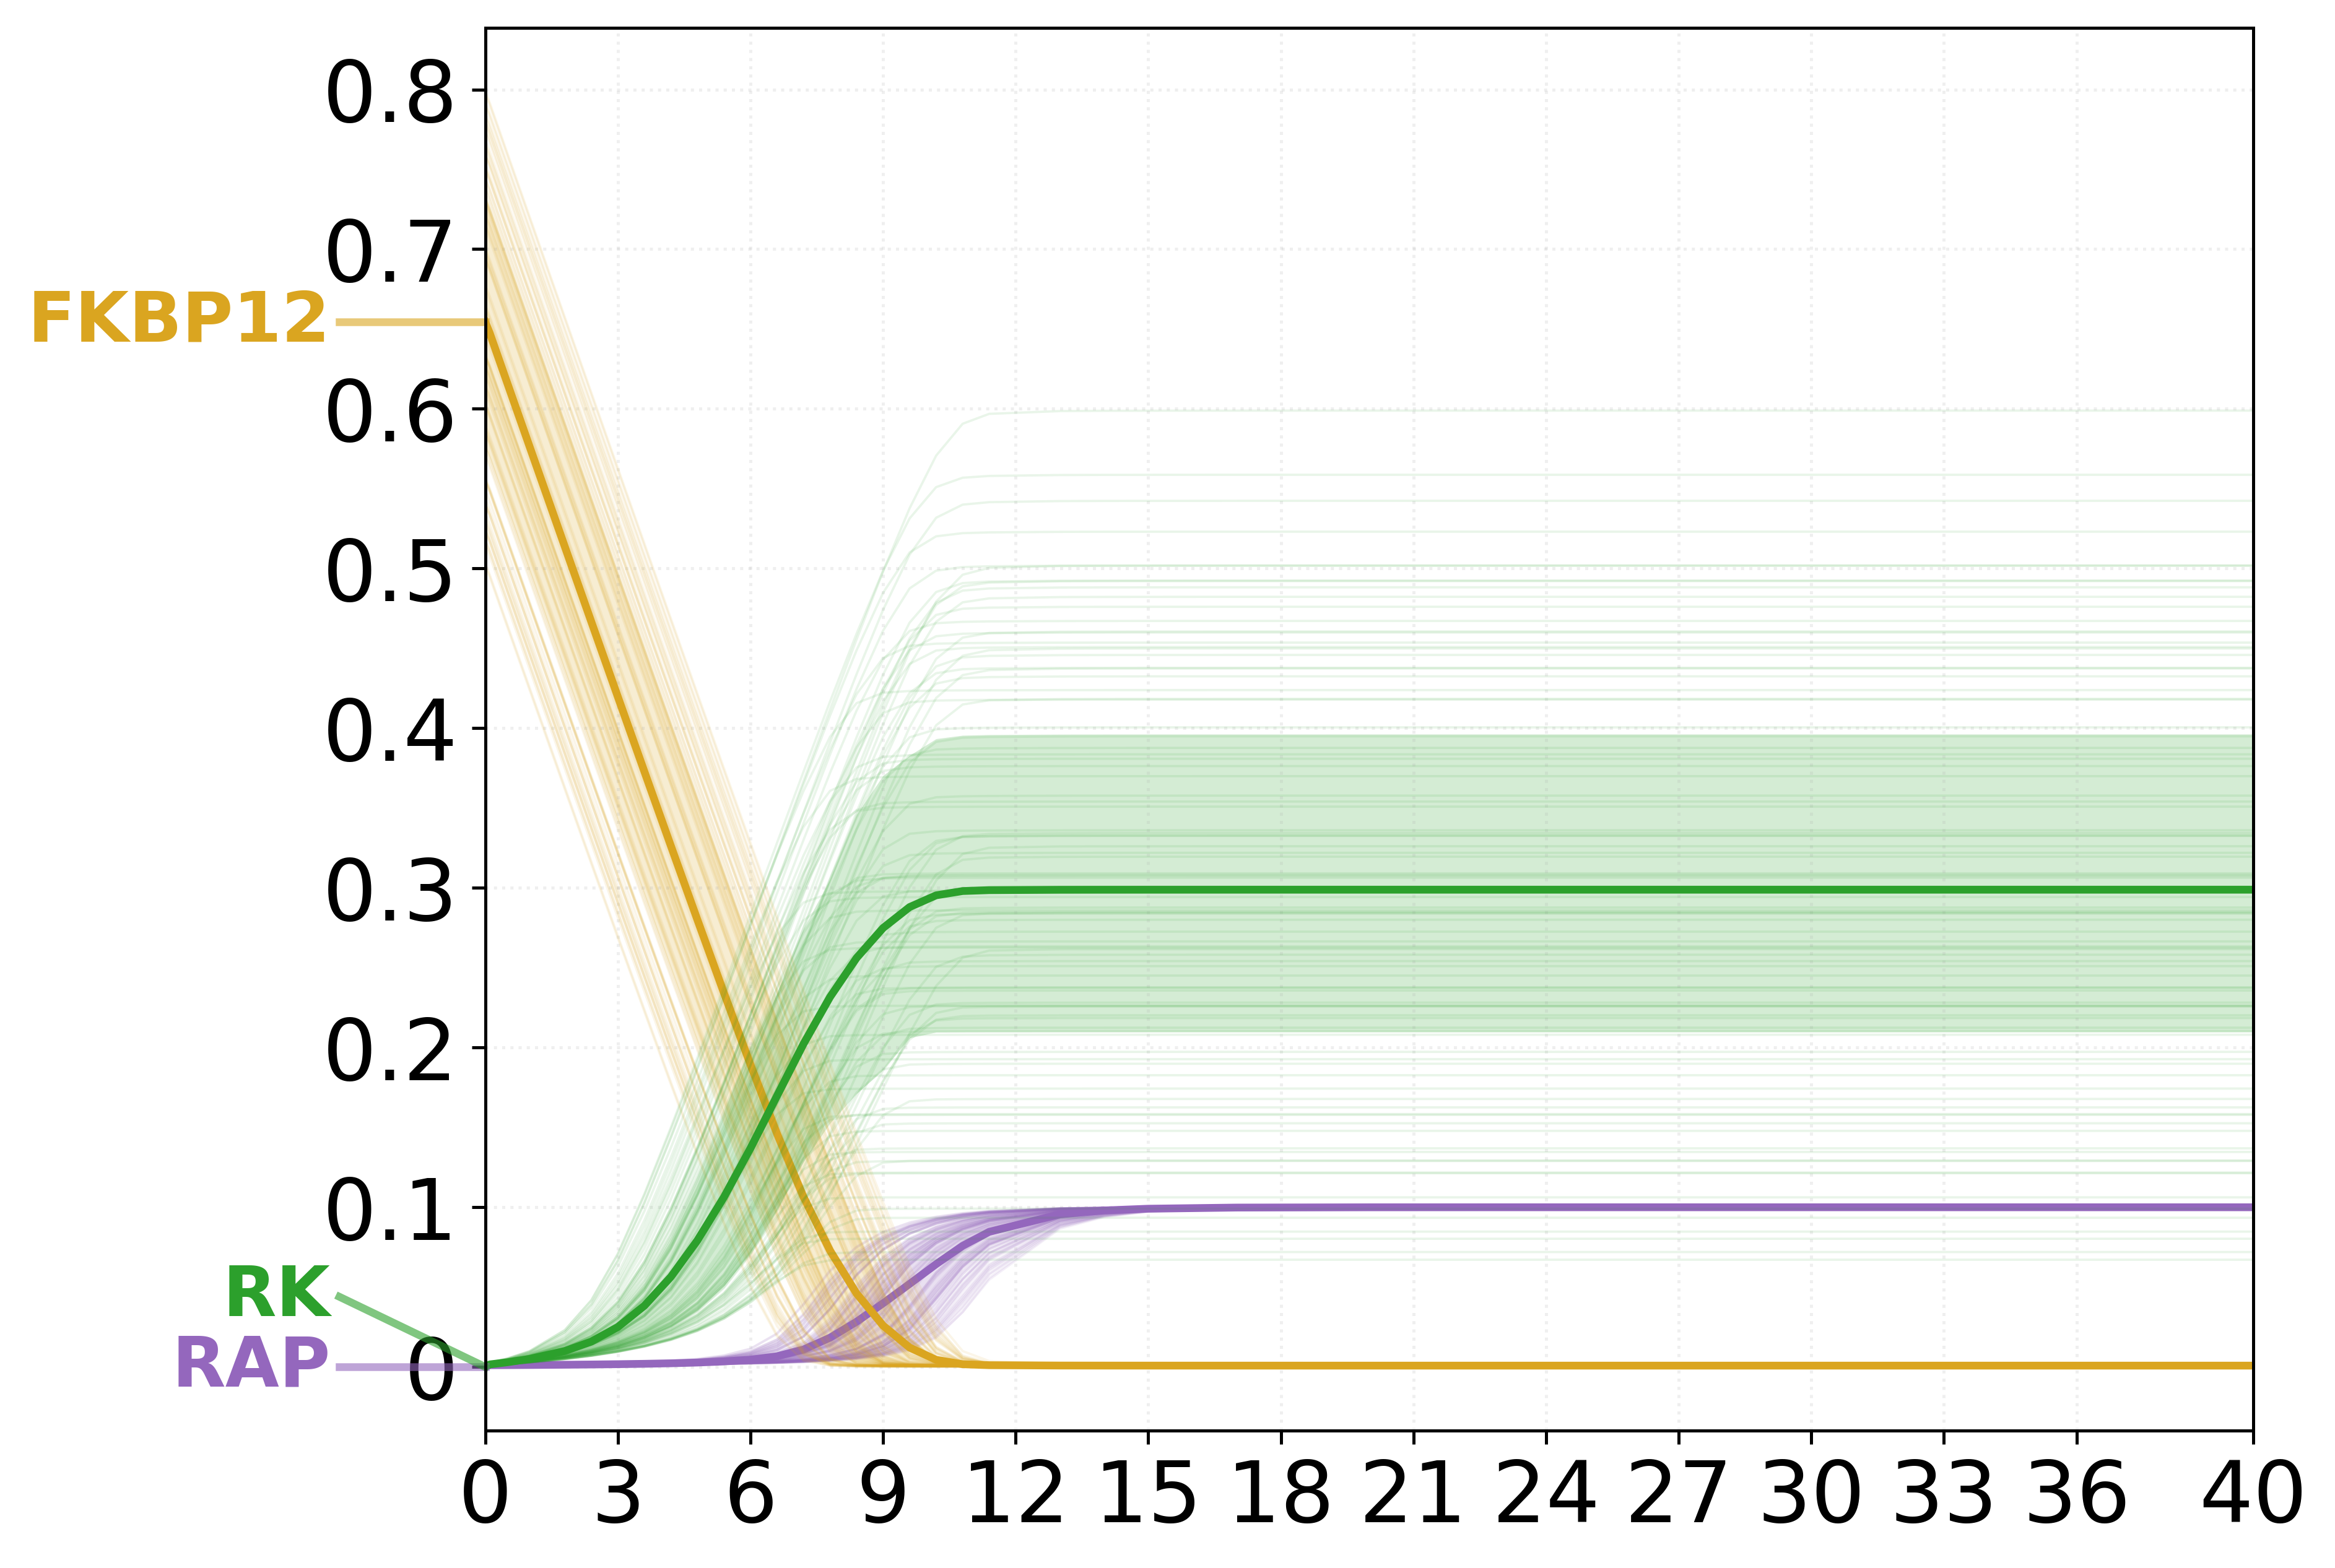

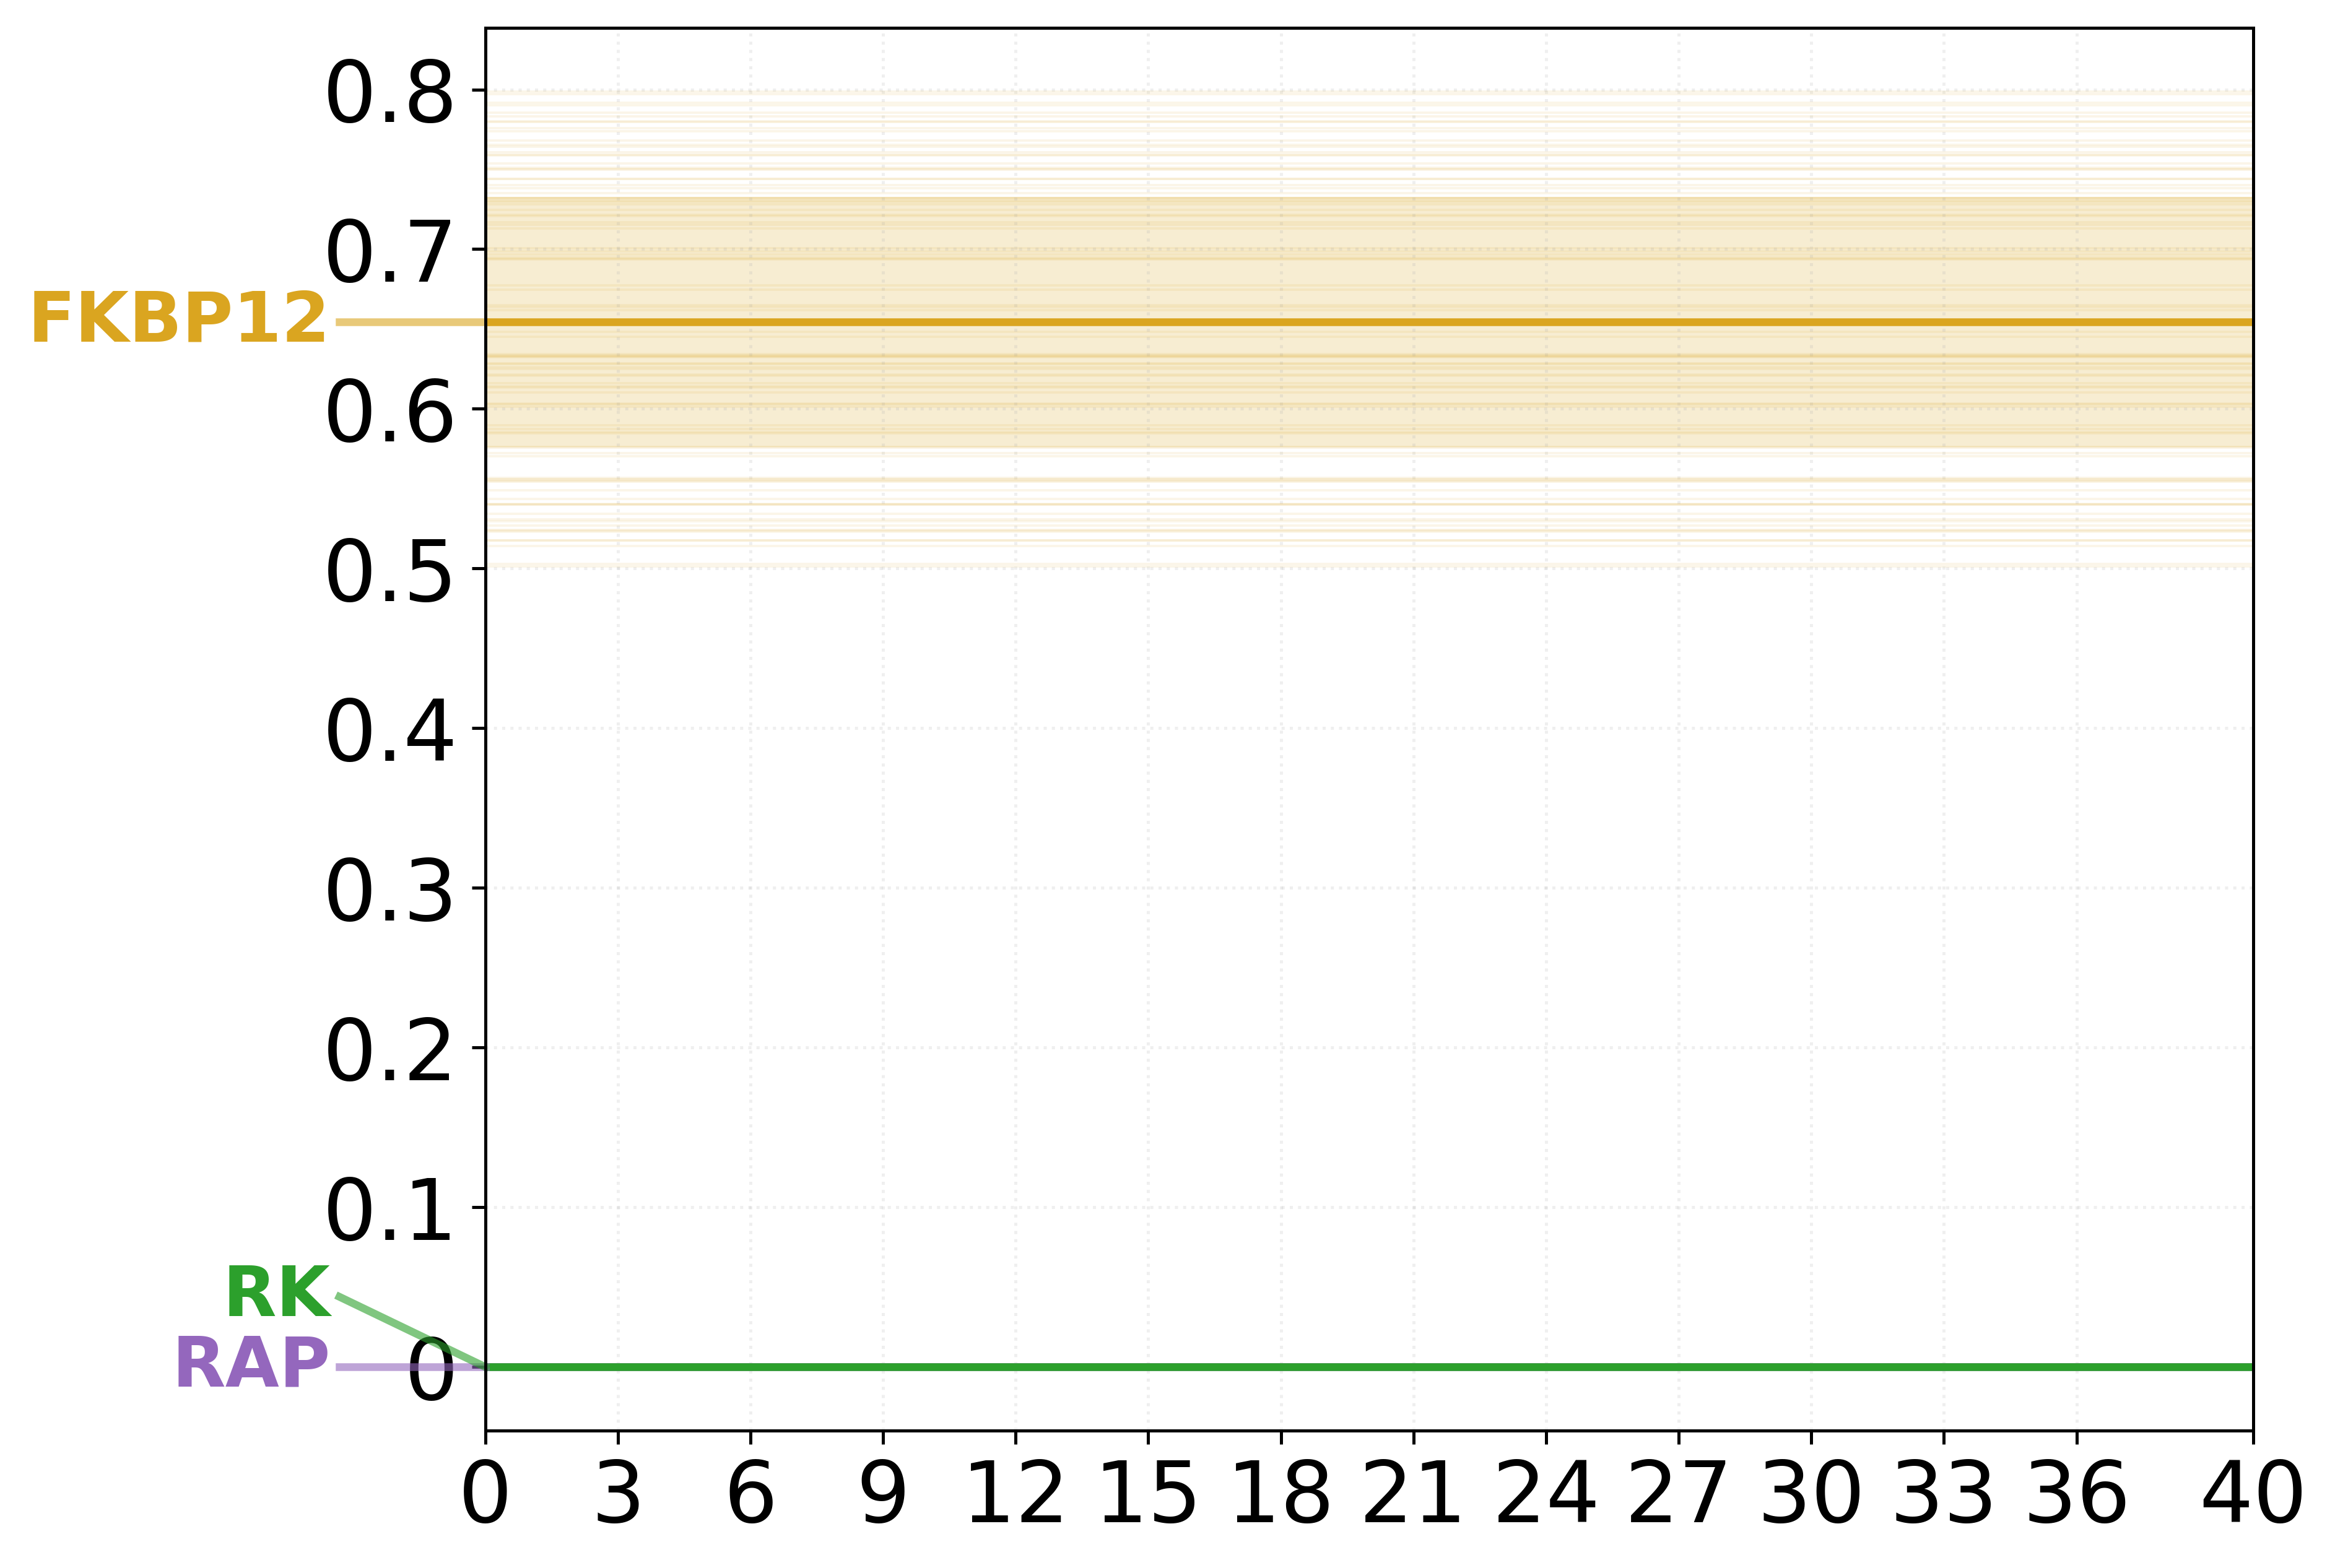

In [62]:
# RAP/FKBP12/RK time courses
font_sizes = {
    "title": 20,
    "suptitle": 22,
    "axis_label": 15,
    "ticks": 22,
    "legend": 17,
    "legend_title": 13,
    "annotation": 18,
    "colorbar_label": 13,
    "colorbar_ticks": 11,
}
concept_font_sizes = {
    **font_sizes,
    "title": 18,
    "axis_label": 22,
    "ticks": 22,
    "annotation": 14,
    "legend": 11,
}

rap_species = ('RAP', 'FKBP12', 'RK')
figs = plot_compare_summary_atp(
    df_dict_a=mechs['rap'].orig_time_sim_df,
    df_dict_b=mechs['no_rap'].orig_time_sim_df,
    label_a='RAP', label_b='NO RAP',
    time_points=t,
    time_units='min',
    x_tick_count=15,
    y_tick_count=8,
    scaling_factor=1e9,
    species=rap_species,
    species_colors={'RAP': 'tab:purple', 'FKBP12': 'goldenrod'},
    layout_mode="condition",
    separate_conditions=True,
    show_iqr=True, show_p80=False,
    show_mean=True, show_median=False,
    sample_trajs=100,
    legend_loc="none",
    curve_labels=True,
    curve_label_min_gap_frac=0.05,
    curve_label_xpad=-3.5,
    curve_label_connectors=True,
    figsize=(8, 6),
    title="",
    font_sizes=font_sizes,
    x_label="",
    y_label="",
    fig_dpi=450,
)

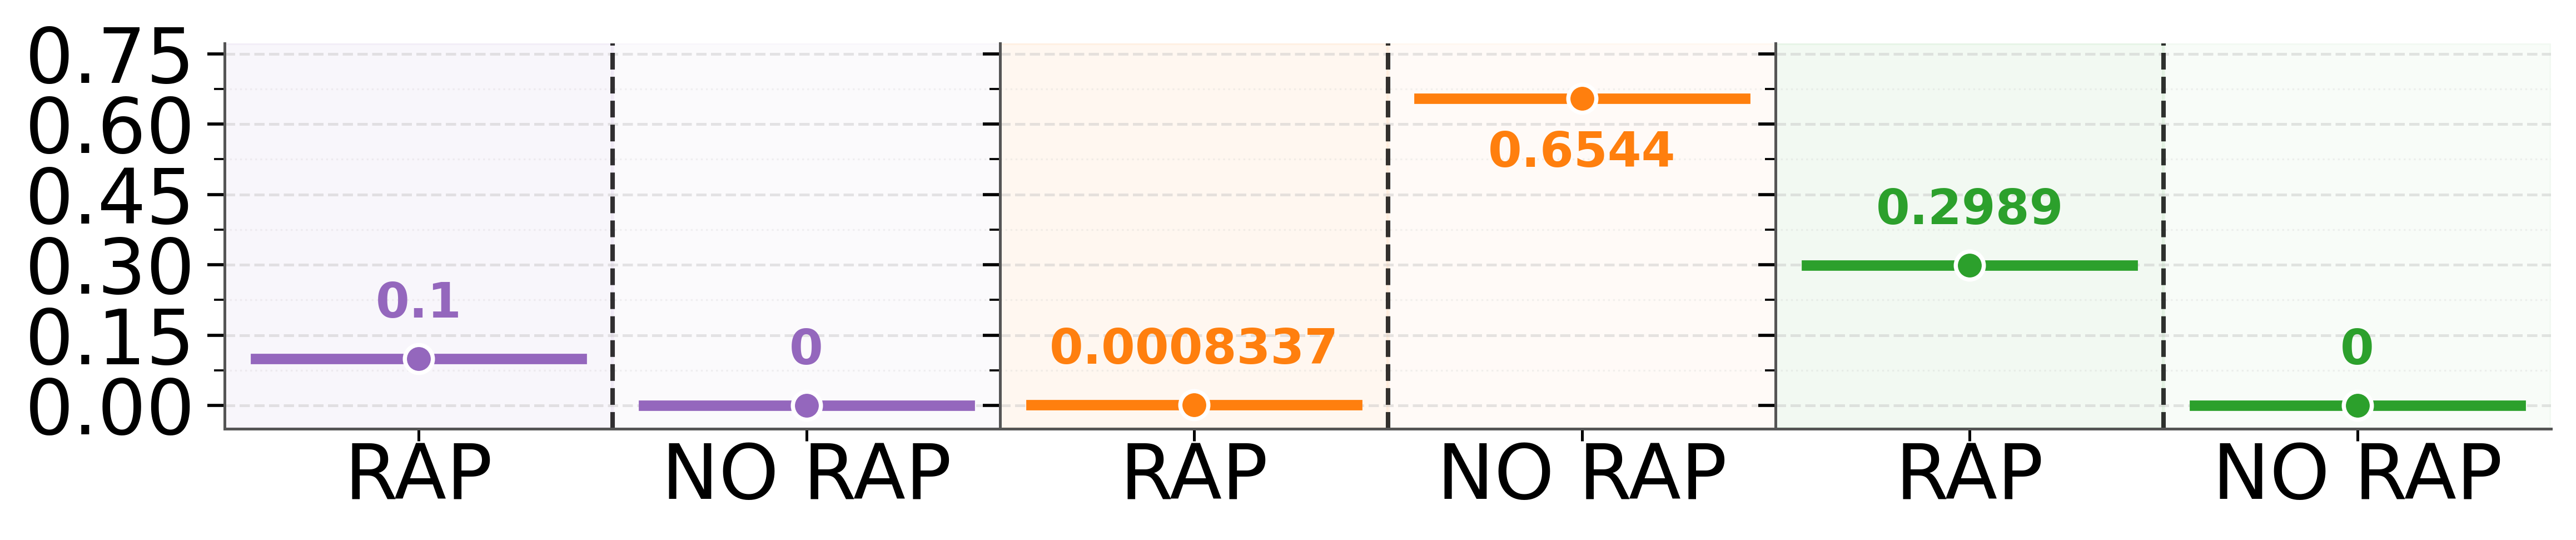

In [63]:
rap_endpoint_fig = plot_endpoint_concept_diagrams(
    df_dict_starvation=mechs['rap'].orig_time_sim_df,
    df_dict_basal=mechs['no_rap'].orig_time_sim_df,
    species=rap_species,
    scaling_factor=1e9,
    color_species_order=rap_species,
    species_colors={'RAP': 'tab:purple'},
    condition_labels=('RAP', 'NO RAP'),
    endpoint_statistic='mean',
    legend_loc='none',
    font_sizes=concept_font_sizes,
    x_label="",
    y_label="",
    title="",
    figsize=(4, 2),
    y_major_ticks=6,
    shared_y_limits=True,
    y_bottom=-0.05,
    transparent_bg=True,
    lower_text_th=0.1,
    upper_text_th=0.5,
    plot_combined=True,
    combined_orientation='horizontal',
    x_pad=0,
    fig_dpi=450,
)

In [64]:
# Starve-style AMPK/MTOR/ULK summary plots for RAP vs Basal

def plot_compare_summary_ampk(
    df_dict_a: Dict[str, pd.DataFrame],
    df_dict_b: Dict[str, pd.DataFrame],
    label_a: str = 'cond A',
    label_b: str = 'cond B',
    species=('ATP','ADP','AMP'),
    dt_minutes=30,
    total_hours=84,
    time_points=None,
    time_units='h',
    x_tick_count: Optional[int] = 15,
    y_tick_count: Optional[int] = 5,
    scaling_factor: float = 1.0,
    # ---- layout switch ----
    layout_mode: str = "species",   # "species" | "condition"
    # ---- stat controls ----
    show_iqr: bool = True,
    show_p80: bool = False,
    show_mean: bool = True,
    show_median: bool = False,
    sample_trajs: int = 0,          # 0 -> no thin trajectories
    traj_alpha: float = 0.10,
    band_alpha_iqr: float = 0.20,
    band_alpha_p80: float = 0.10,
    legend_pos: str = "below",      # "below" | "above" | "inside"
    species_colors: Optional[Mapping[str, str]] = None,
    # -----------------------
    show_axp: bool = True,          # only used if plotting the AXP trio
    figsize=(12, 8),
    curve_labels: bool = False,
    curve_label_min_gap_frac: float = 0.02,
    curve_label_xpad: float = -3.0,
    curve_label_connectors: bool = True,
    # ---- separate figures ----
    multi_fig: bool = False,        # one fig per *species*
    separate_conditions: bool = False,  # only used if layout_mode="condition"
    user_title='',
    curve_label_xfrac=1,
    curve_label_y_offset_frac=0.02,
    title=None,
    x_label=None,
    y_label=None,
    text_overrides=None,
    font_sizes=None,
    legend_loc=None,
    legend_bbox_to_anchor=None,
    fig_dpi=300,
    transparent_bg: bool = False,
    user_ylim=None
):
    """
    Compare conditions A vs B for the given species.

    layout_mode = "species":
        One subplot per species. Each subplot shows both conditions.

    layout_mode = "condition":
        Two panels (A, B). Each panel shows all species for that condition.

    multi_fig = True:
        Instead of one figure for all species, return a list of figures, one
        per species (using the chosen layout_mode).

    separate_conditions = True (with layout_mode="condition"):
        Instead of a single figure with two subplots, return two separate
        figures: (fig_A, fig_B).

    ``x_tick_count`` and ``y_tick_count`` set target major-tick counts. Nearby
    readable positions with at most one decimal digit take precedence over an
    exact count. Use ``None`` for Matplotlib's automatic tick placement.
    ``species_colors`` is a partial mapping: only named species override the
    normal color cycle, while every omitted species keeps its default color.
    """
    if layout_mode not in {"species", "condition"}:
        raise ValueError('layout_mode must be "species" or "condition".')

    species = _normalize_species(species)

    # --- one fig per species if requested -------------------
    if multi_fig and len(species) > 1:
        figs = []
        for sp in species:
            figs.append(
                plot_compare_summary_ampk(
                    df_dict_a=df_dict_a,
                    df_dict_b=df_dict_b,
                    label_a=label_a,
                    label_b=label_b,
                    species=(sp,),
                    dt_minutes=dt_minutes,
                    total_hours=total_hours,
                    time_points=time_points,
                    time_units=time_units,
                    x_tick_count=x_tick_count,
                    y_tick_count=y_tick_count,
                    scaling_factor=scaling_factor,
                    layout_mode=layout_mode,
                    show_iqr=show_iqr,
                    show_p80=show_p80,
                    show_mean=show_mean,
                    show_median=show_median,
                    sample_trajs=sample_trajs,
                    traj_alpha=traj_alpha,
                    band_alpha_iqr=band_alpha_iqr,
                    band_alpha_p80=band_alpha_p80,
                    legend_pos=legend_pos,
                    species_colors=species_colors,
                    show_axp=show_axp,
                    figsize=figsize,
                    curve_labels=curve_labels,
                    curve_label_min_gap_frac=curve_label_min_gap_frac,
                    curve_label_xpad=curve_label_xpad,
                    curve_label_connectors=curve_label_connectors,
                    multi_fig=False,
                    separate_conditions=separate_conditions,
                    user_title=user_title,
                    curve_label_xfrac=curve_label_xfrac,
                    curve_label_y_offset_frac=curve_label_y_offset_frac,
                    title=title,
                    x_label=x_label,
                    y_label=y_label,
                    text_overrides=text_overrides,
                    font_sizes=font_sizes,
                    legend_loc=legend_loc,
                    legend_bbox_to_anchor=legend_bbox_to_anchor,
                    fig_dpi=fig_dpi,
                    transparent_bg=transparent_bg,
                    user_ylim=user_ylim,
                )
            )
        return figs
    # --------------------------------------------------------

    if time_points is not None:
        t_h = np.asarray(time_points, dtype=float)
        n_expected = len(t_h)
    else:
        n_expected = int(total_hours*60/dt_minutes + 1)
        t_h = None

    idx_a, Xa = _stack_runs(df_dict_a, species, n_expected)
    idx_b, Xb = _stack_runs(df_dict_b, species, n_expected)
    Xa = Xa * scaling_factor
    Xb = Xb * scaling_factor
    if t_h is not None and t_h.shape[0] != Xa.shape[1]:
        t_h = t_h[:Xa.shape[1]]
    if t_h is None:
        t_h_a = (idx_a.values - 1) * dt_minutes / 60.0
        t_h_b = (idx_b.values - 1) * dt_minutes / 60.0
    else:
        t_h_a = t_h
        t_h_b = t_h

    qa10, qa25, qamed, qa75, qa90, qamean = _summary(Xa)
    qb10, qb25, qbmed, qb75, qb90, qbmean = _summary(Xb)

    rng = np.random.default_rng(0)
    samp_a = rng.choice(Xa.shape[0], size=min(sample_trajs, Xa.shape[0]),
                        replace=False) if sample_trajs else []
    samp_b = rng.choice(Xb.shape[0], size=min(sample_trajs, Xb.shape[0]),
                        replace=False) if sample_trajs else []

    legend_data = {label_a: {}, label_b: {}}
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
    condition_species_colors = {
        sp: color_cycle[index % len(color_cycle)]
        for index, sp in enumerate(species)
    }
    if species_colors:
        condition_species_colors.update(species_colors)

    # ---------------- LAYOUT 1: one subplot per species ----------------
    if layout_mode == "species":
        fig, axes = plt.subplots(
            1, len(species), figsize=figsize, sharex=True, dpi=fig_dpi,
        )
        if len(species) == 1:
            axes = [axes]

        for si, sp in enumerate(species):
            ax = axes[si]

            for ridx in samp_a:
                ax.plot(t_h_a, Xa[ridx, :, si], lw=0.6, alpha=traj_alpha)
            for ridx in samp_b:
                ax.plot(t_h_b, Xb[ridx, :, si], lw=0.6, alpha=traj_alpha)

            if show_p80:
                ax.fill_between(t_h_a, qa10[:, si], qa90[:, si],
                                alpha=band_alpha_p80, linewidth=0,
                                label=f'{label_a} 10-90%')
            if show_iqr:
                ax.fill_between(t_h_a, qa25[:, si], qa75[:, si],
                                alpha=band_alpha_iqr, linewidth=0,
                                label=f'{label_a} IQR')

            if show_p80:
                ax.fill_between(t_h_b, qb10[:, si], qb90[:, si],
                                alpha=band_alpha_p80, linewidth=0,
                                label=f'{label_b} 10-90%')
            if show_iqr:
                ax.fill_between(t_h_b, qb25[:, si], qb75[:, si],
                                alpha=band_alpha_iqr, linewidth=0,
                                label=f'{label_b} IQR')

            if curve_labels:
                y0_a = qamean[0, si]
                y0_b = qbmean[0, si]
                ax.text(-2.5, y0_a, f"{label_a}", color='tab:blue',
                        va='center', ha='right', fontsize=14, weight='bold')
                ax.text(-2.5, y0_b, f"{label_b}", color='tab:orange',
                        va='center', ha='right', fontsize=14, weight='bold')

            if show_mean:
                ax.plot(t_h_a, qamean[:, si], lw=2, label=f'{label_a} mean')
                ax.plot(t_h_b, qbmean[:, si], lw=2, label=f'{label_b} mean')
            if show_median:
                ax.plot(t_h_a, qamed[:, si], lw=1, linestyle='--',
                        label=f'{label_a} median')
                ax.plot(t_h_b, qbmed[:, si], lw=1, linestyle='--',
                        label=f'{label_b} median')

            ax.set_title(
                user_title or f"Time Profile of {sp} Dynamics for N = {Xa.shape[0]} Simulations",
                fontsize=20
            )
            if time_points is None:
                ax.set_xlim(0, total_hours)
                ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            else:
                ax.set_xlim(float(t_h_a[0]), float(t_h_a[-1]))
            if si == 0:
                ax.set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
            ax.set_xlabel(f'time [{time_units}]', fontsize=12)
            ax.grid(alpha=0.2, linestyle=':')
            _apply_tick_counts(ax, x_tick_count, y_tick_count)

        # legend for layout_mode="species"
        handles, labels = axes[0].get_legend_handles_labels()
        ncol = 6

        if _legend_is_disabled(legend_pos, legend_loc):
            fig.tight_layout()
        elif legend_pos == "below":
            fig.legend(handles, labels, frameon=False, loc='lower center',
                       bbox_to_anchor=(0.5, -0.01), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0.06, 1, 1])
        elif legend_pos == "above":
            fig.legend(handles, labels, frameon=False, loc='upper center',
                       bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0, 1, 0.94])
        else:
            axes[-1].legend(handles, labels, frameon=False, loc='upper right')
            fig.tight_layout()

        _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
        _apply_plot_text_controls(
            fig, axes, panel_keys=species, title=title,
            x_label=x_label, y_label=y_label,
            text_overrides=text_overrides, font_sizes=font_sizes,
        )
        _apply_figure_background(fig, transparent_bg)
        return fig

    # ---------------- LAYOUT 2: condition layout ----------------
    # option A: separate figures per condition
    if separate_conditions:
        figs = []

        def _single_condition_fig(t_h, X, q10, q25, qmed, q75, q90, qmean,
                                  samp_idx, cond_label):
            fig_c, ax = plt.subplots(1, 1, figsize=figsize, dpi=fig_dpi)

            sp_colors = {}
            for si, sp in enumerate(species):
                species_color = condition_species_colors[sp]
                for ridx in samp_idx:
                    ax.plot(
                        t_h, X[ridx, :, si], color=species_color,
                        lw=0.6, alpha=traj_alpha, label='_nolegend_',
                    )

                if show_p80:
                    ax.fill_between(t_h, q10[:, si], q90[:, si],
                                    color=species_color,
                                    alpha=band_alpha_p80, linewidth=0,
                                    label='_nolegend_')
                if show_iqr:
                    ax.fill_between(t_h, q25[:, si], q75[:, si],
                                    color=species_color,
                                    alpha=band_alpha_iqr, linewidth=0,
                                    label='_nolegend_')

                if show_mean:
                    line = ax.plot(t_h, qmean[:, si], color=species_color, lw=2,
                                   label=f"{sp} mean")[0]
                    sp_colors[sp] = line.get_color()
                if show_median:
                    ax.plot(t_h, qmed[:, si], color=species_color,
                            lw=1, linestyle='--',
                            label=f"{sp} median")

            if show_axp and set(species) == {'ATP','ADP','AMP'}: #####################################x
                ax.plot(t_h, qmean.sum(axis=1), lw=2.2, linestyle=':',
                        label='AXP mean')

            if cond_label == 'RAP':
                default_title = f"RAP Treated Dynamics for N = {X.shape[0]} simulations"
            else:
                default_title = f"Basal State Dynamics for N = {X.shape[0]} simulations"
            ax.set_title(user_title or default_title, fontsize=24)
            if time_points is None:
                ax.set_xlim(0, total_hours)
                ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            else:
                ax.set_xlim(float(t_h[0]), float(t_h[-1]))
            ax.tick_params(axis='x', labelsize=16)
            ax.tick_params(axis='y', labelsize=16)
            ax.set_xlabel(f'time [{time_units}]', fontsize=18)
            ax.set_ylabel(r'concentration [mM]', fontsize=20)
            ax.grid(alpha=0.2, linestyle=':')
            _apply_tick_counts(ax, x_tick_count, y_tick_count)

            # left-side species labels if requested
                        # curve labels with connectors at arbitrary x-position
            if curve_labels and show_mean:
                # --- choose x-position along the curve ---
                x0, x1 = t_h[0], t_h[-1]
                if 0.0 <= curve_label_xfrac <= 1.0:
                    # interpret as fraction of [x0, x1]
                    x_target = x0 + curve_label_xfrac * (x1 - x0)
                else:
                    # interpret as absolute time in hours
                    x_target = curve_label_xfrac
                x_target = np.clip(x_target, x0, x1)

                # --- y-values of each curve at that x (via interpolation) ---
                y_at_x = [
                    np.interp(x_target, t_h, qmean[:, si])
                    for si in range(len(species))
                ]

                # --- spread vertically to avoid overlaps ---
                y_min, y_max = ax.get_ylim()
                y_range = max(1e-12, (y_max - y_min))
                y_spread = _spread(y_at_x, curve_label_min_gap_frac * y_range)

                # optional extra offset above/below the curve
                y_labels = [
                    y_s + curve_label_y_offset_frac * y_range
                    for y_s in y_spread
                ]

                # x-position of labels: a bit to the right of x_target
                curve_label_x = x_target + curve_label_xpad

                # extend x-limits if labels would be outside the axes
                if curve_label_x > x1:
                    ax.set_xlim(x0, curve_label_x + 0.5)

                for sp, y_lab, y_true in zip(species, y_labels, y_at_x):
                    col = sp_colors.get(sp, 'black')
                    ax.text(
                        curve_label_x, y_lab, sp,
                        color=col, va='center', ha='left',
                        fontsize=14, weight='bold'
                    )
                    if curve_label_connectors:
                        ax.plot(
                            [x_target, curve_label_x - 0.2],
                            [y_true,  y_lab],
                            lw=2.0, alpha=0.6, color=col,
                            label='_nolegend_',
                            clip_on=False
                        )


            handles_c, labels_c = ax.get_legend_handles_labels()
            if _legend_is_disabled(legend_pos, legend_loc):
                fig_c.tight_layout()
            elif legend_pos == "below":
                fig_c.legend(handles_c, labels_c, frameon=False, loc='lower center',
                             bbox_to_anchor=(0.5, -0.01), ncol=len(labels_c),
                             fontsize=12)
                fig_c.tight_layout(rect=[0, 0.06, 1, 1])
            elif legend_pos == "above":
                fig_c.legend(handles_c, labels_c, frameon=False, loc='upper center',
                             bbox_to_anchor=(0.5, 1.15), ncol=len(labels_c),
                             fontsize=12)
                fig_c.tight_layout(rect=[0, 0, 1, 0.94])
            else:
                ax.legend(frameon=False, loc='upper right')
                fig_c.tight_layout()

            _apply_legend_position(
                fig_c, legend_loc, legend_bbox_to_anchor,
            )
            _apply_plot_text_controls(
                fig_c, [ax], panel_keys=[cond_label], title=title,
                x_label=x_label, y_label=y_label,
                text_overrides=text_overrides, font_sizes=font_sizes,
            )
            _apply_figure_background(fig_c, transparent_bg)
            return fig_c

        figs.append(_single_condition_fig(
            t_h_a, Xa, qa10, qa25, qamed, qa75, qa90, qamean,
            samp_a, label_a
        ))
        figs.append(_single_condition_fig(
            t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90, qbmean,
            samp_b, label_b
        ))
        return figs

    # option B: original behaviour - one figure with two subplots
    fig, axes = plt.subplots(
        1, 2, figsize=figsize, sharex=True, sharey=True, dpi=fig_dpi,
    )

    def _plot_condition_panel(ax, t_h, X, q10, q25, qmed, q75, q90, qmean,
                              samp_idx, cond_label, bucket):
        first_for_stat = True
        sp_colors = {}

        for si, sp in enumerate(species):
            species_color = condition_species_colors[sp]
            for ridx in samp_idx:
                ax.plot(
                    t_h, X[ridx, :, si], color=species_color,
                    lw=0.6, alpha=traj_alpha, label='_nolegend_',
                )

            if show_p80:
                band = ax.fill_between(
                    t_h, q10[:, si], q90[:, si],
                    color=species_color, alpha=band_alpha_p80, linewidth=0
                )
                if first_for_stat:
                    bucket[('P80', None)] = band
            if show_iqr:
                band = ax.fill_between(
                    t_h, q25[:, si], q75[:, si],
                    color=species_color, alpha=band_alpha_iqr, linewidth=0
                )
                if first_for_stat:
                    bucket[('IQR', None)] = band

            if show_mean:
                line = ax.plot(t_h, qmean[:, si], color=species_color, lw=2)[0]
                sp_colors[sp] = line.get_color()
                bucket[('mean', sp)] = line
            if show_median:
                line = ax.plot(
                    t_h, qmed[:, si], color=species_color,
                    lw=1, linestyle='--',
                )[0]
                bucket[('median', sp)] = line

            first_for_stat = False

        ax.set_title(
            user_title or f"AXP Dynamics in {cond_label} for N = {X.shape[0]} simulations",
            fontsize=15
        )
        if time_points is None:
            ax.set_xlim(0, total_hours)
            ax.set_xticks(np.arange(0, total_hours+0.1, 6))
        else:
            ax.set_xlim(float(t_h[0]), float(t_h[-1]))
        ax.set_xlabel(f'time [{time_units}]', fontsize=12)
        ax.grid(alpha=0.2, linestyle=':')
        _apply_tick_counts(ax, x_tick_count, y_tick_count)

        if curve_labels and show_mean:
            y0s = [qmean[0, si] for si in range(len(species))]
            y_min, y_max = ax.get_ylim()
            y_range = max(1e-12, (y_max - y_min))
            y_labs = _spread(y0s, curve_label_min_gap_frac * y_range)

            for sp, y_lab, y_true in zip(species, y_labs, y0s):
                col = sp_colors.get(sp, 'black')
                ax.text(curve_label_xpad, y_lab, sp,
                        color=col, va='center', ha='right',
                        fontsize=14, weight='bold')
                if curve_label_connectors:
                    ax.plot([curve_label_xpad + 0.2, 0],
                            [y_lab, y_true],
                            lw=2.0, alpha=0.6, color=col,
                            label='_nolegend_',
                            clip_on=False)

        ax.set_ylim(user_ylim) if user_ylim is not None else None

    _plot_condition_panel(axes[0], t_h_a, Xa, qa10, qa25, qamed, qa75, qa90,
                          qamean, samp_a, label_a, legend_data[label_a])
    _plot_condition_panel(axes[1], t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90,
                          qbmean, samp_b, label_b, legend_data[label_b])

    axes[0].set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
    axes[1].tick_params(labelleft=True)

    if show_axp and set(species) == {'ATP','ADP','AMP'}:
        line_a = axes[0].plot(t_h_a, qamean.sum(axis=1),
                              lw=1.2, linestyle=':')[0]
        line_b = axes[1].plot(t_h_b, qbmean.sum(axis=1),
                              lw=1.2, linestyle=':')[0]
        legend_data[label_a][('AXP_mean', None)] = line_a
        legend_data[label_b][('AXP_mean', None)] = line_b

    # ---- shared legend for this layout ----
    if not _legend_is_disabled(legend_pos, legend_loc) and legend_pos in {"below", "above"}:
        cols = []
        if show_iqr:
            cols.append(('IQR', None))
        if show_p80:
            cols.append(('P80', None))
        for sp in species:
            if show_mean:
                cols.append(('mean', sp))
            if show_median:
                cols.append(('median', sp))
        if show_axp and set(species) == {'ATP','ADP','AMP'}:
            cols.append(('AXP_mean', None))

        def desc_str(key):
            kind, sp = key
            if kind == 'IQR':
                return 'IQR'
            if kind == 'P80':
                return '10-90%'
            if kind == 'mean' and sp is not None:
                return f'{sp} mean'
            if kind == 'median' and sp is not None:
                return f'{sp} median'
            if kind == 'AXP_mean':
                return 'AXP mean'
            return str(key)

        handles, labels = [], []
        for cond_label in (label_a, label_b):
            bucket = legend_data[cond_label]
            for key in cols:
                h = bucket.get(key)
                if h is not None:
                    handles.append(h)
                    labels.append(f"{cond_label} {desc_str(key)}")

        ncol = len(cols) if cols else 1

        if legend_pos == "below":
            fig.legend(handles, labels, frameon=False, loc='lower center',
                       bbox_to_anchor=(0.5, -0.01), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0.06, 1, 1])
        else:  # "above"
            fig.legend(handles, labels, frameon=False, loc='upper center',
                       bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0, 1, 0.94])
    elif not _legend_is_disabled(legend_pos, legend_loc):
        axes[-1].legend(frameon=False, loc='upper right')
        fig.tight_layout()
    else:
        fig.tight_layout()

    _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
    _apply_plot_text_controls(
        fig, axes, panel_keys=[label_a, label_b], title=title,
        x_label=x_label, y_label=y_label,
        text_overrides=text_overrides, font_sizes=font_sizes,
    )
    _apply_figure_background(fig, transparent_bg)
    return fig

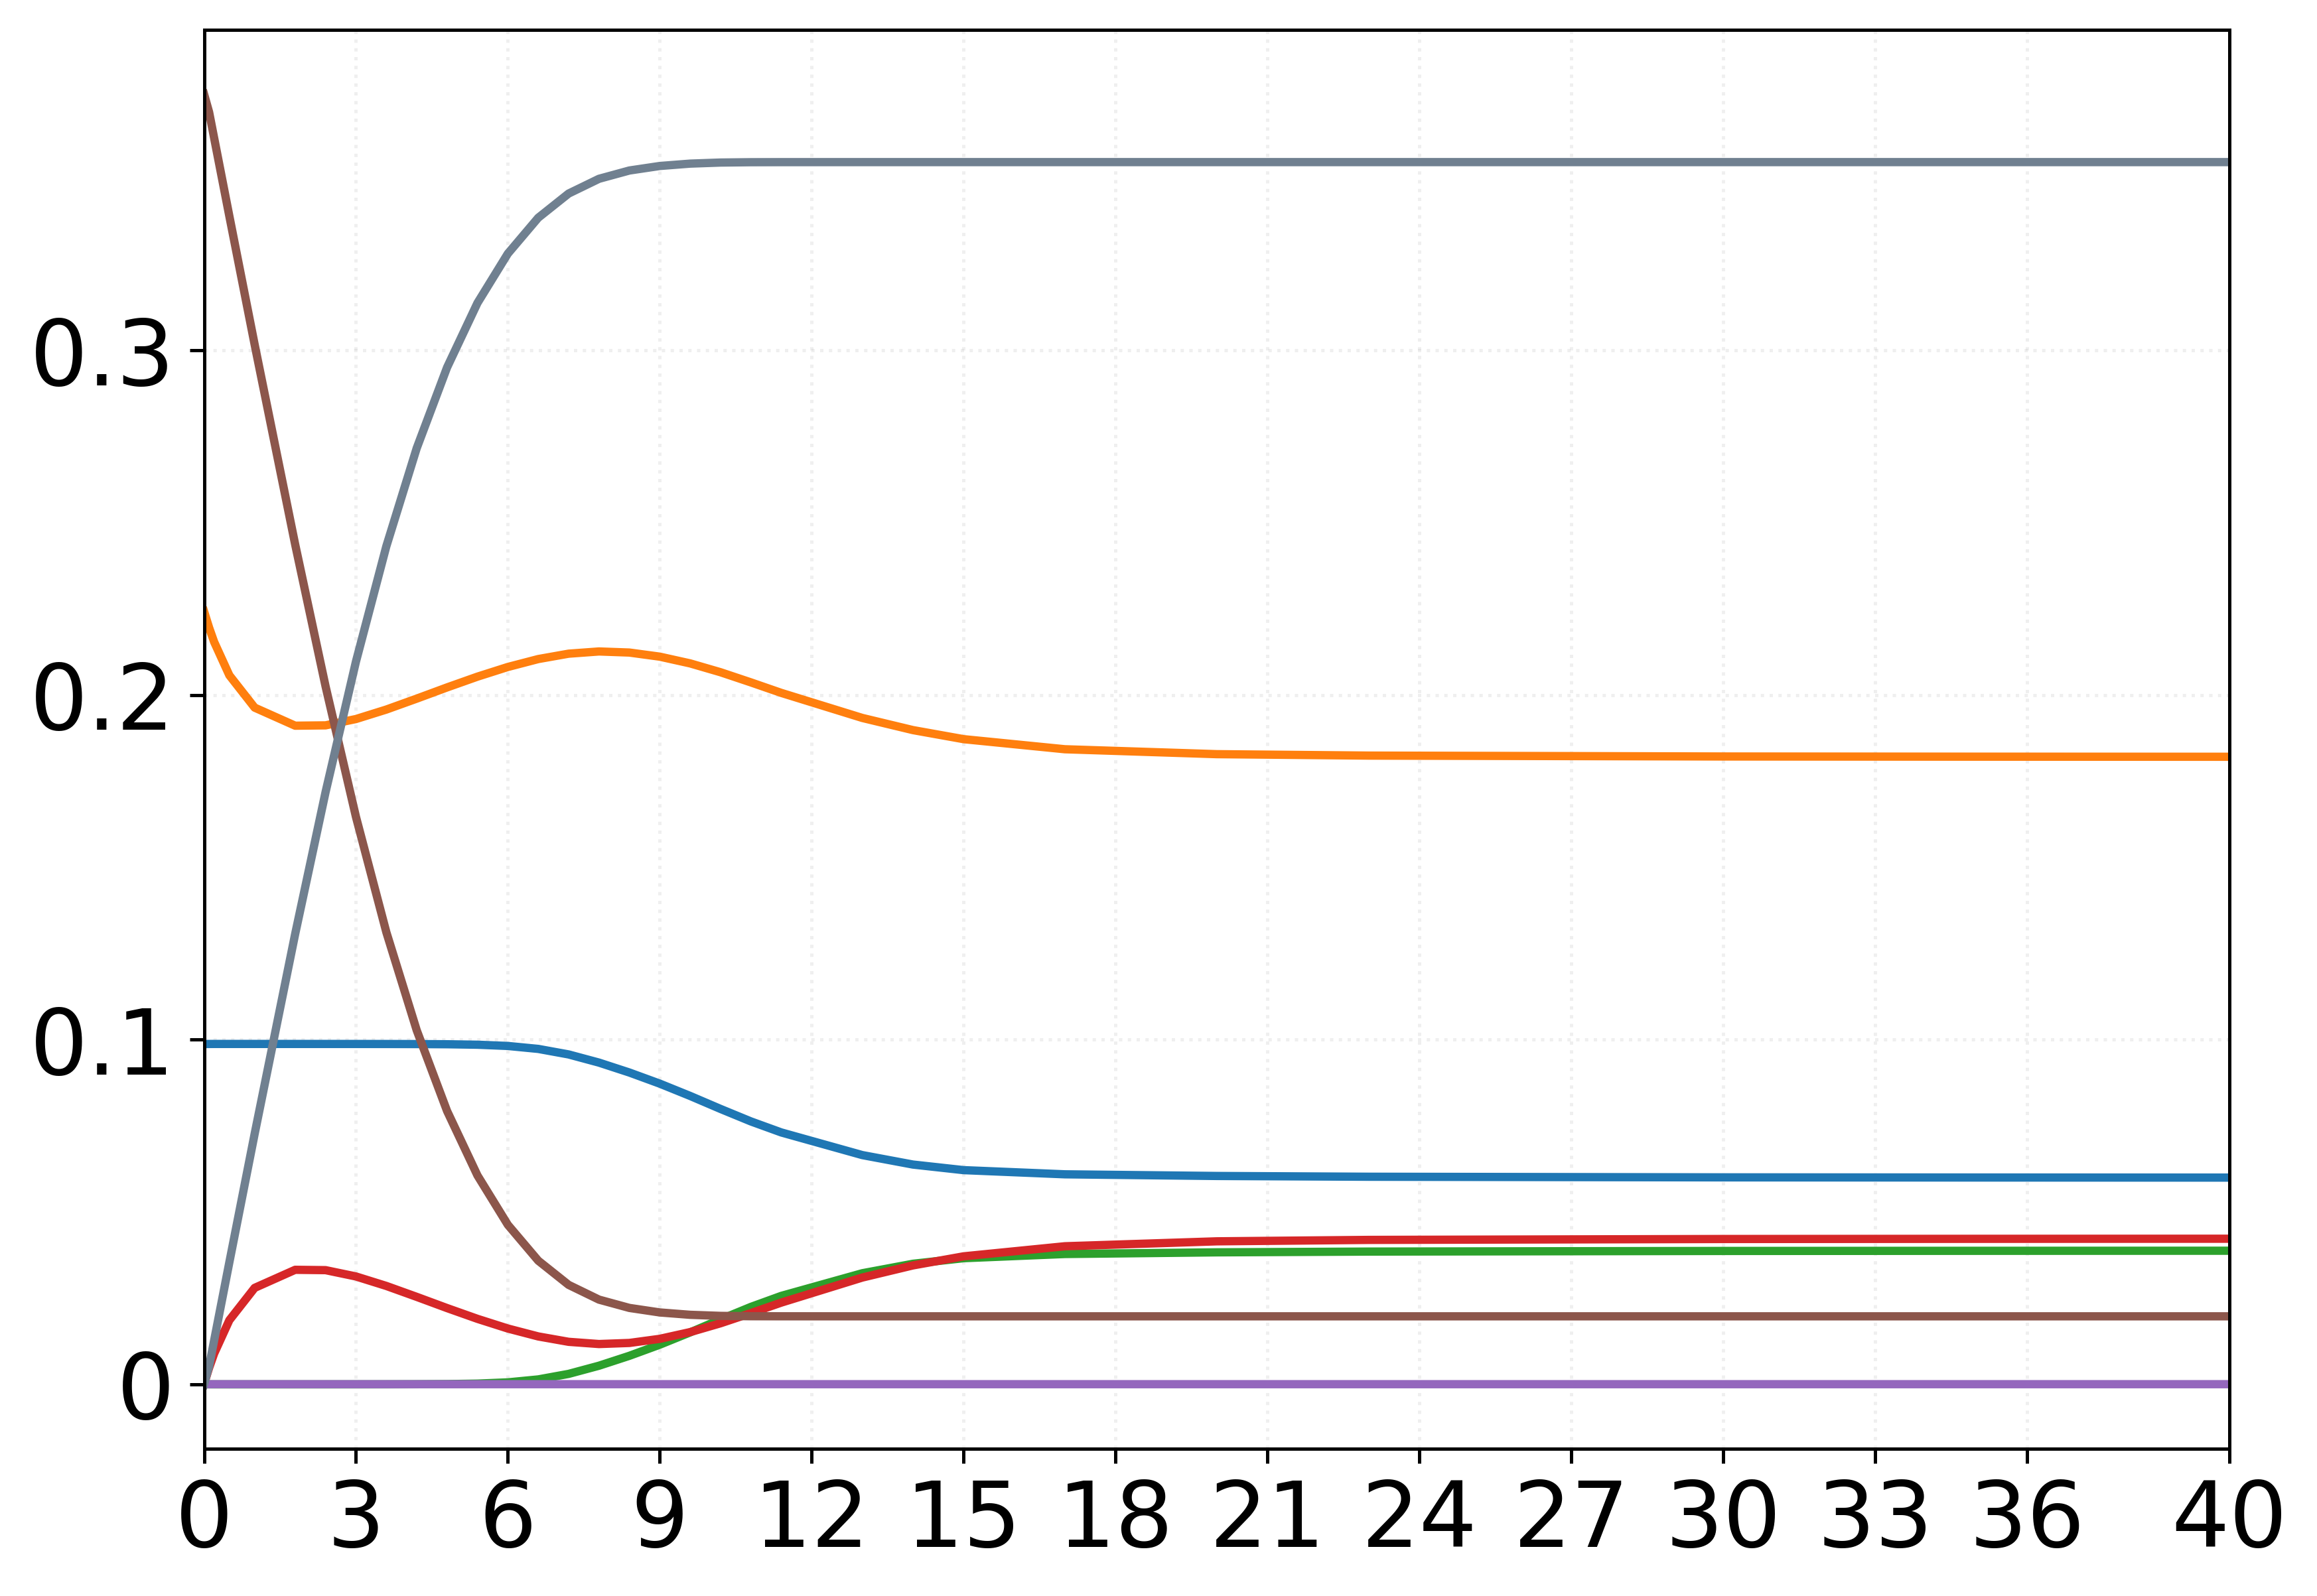

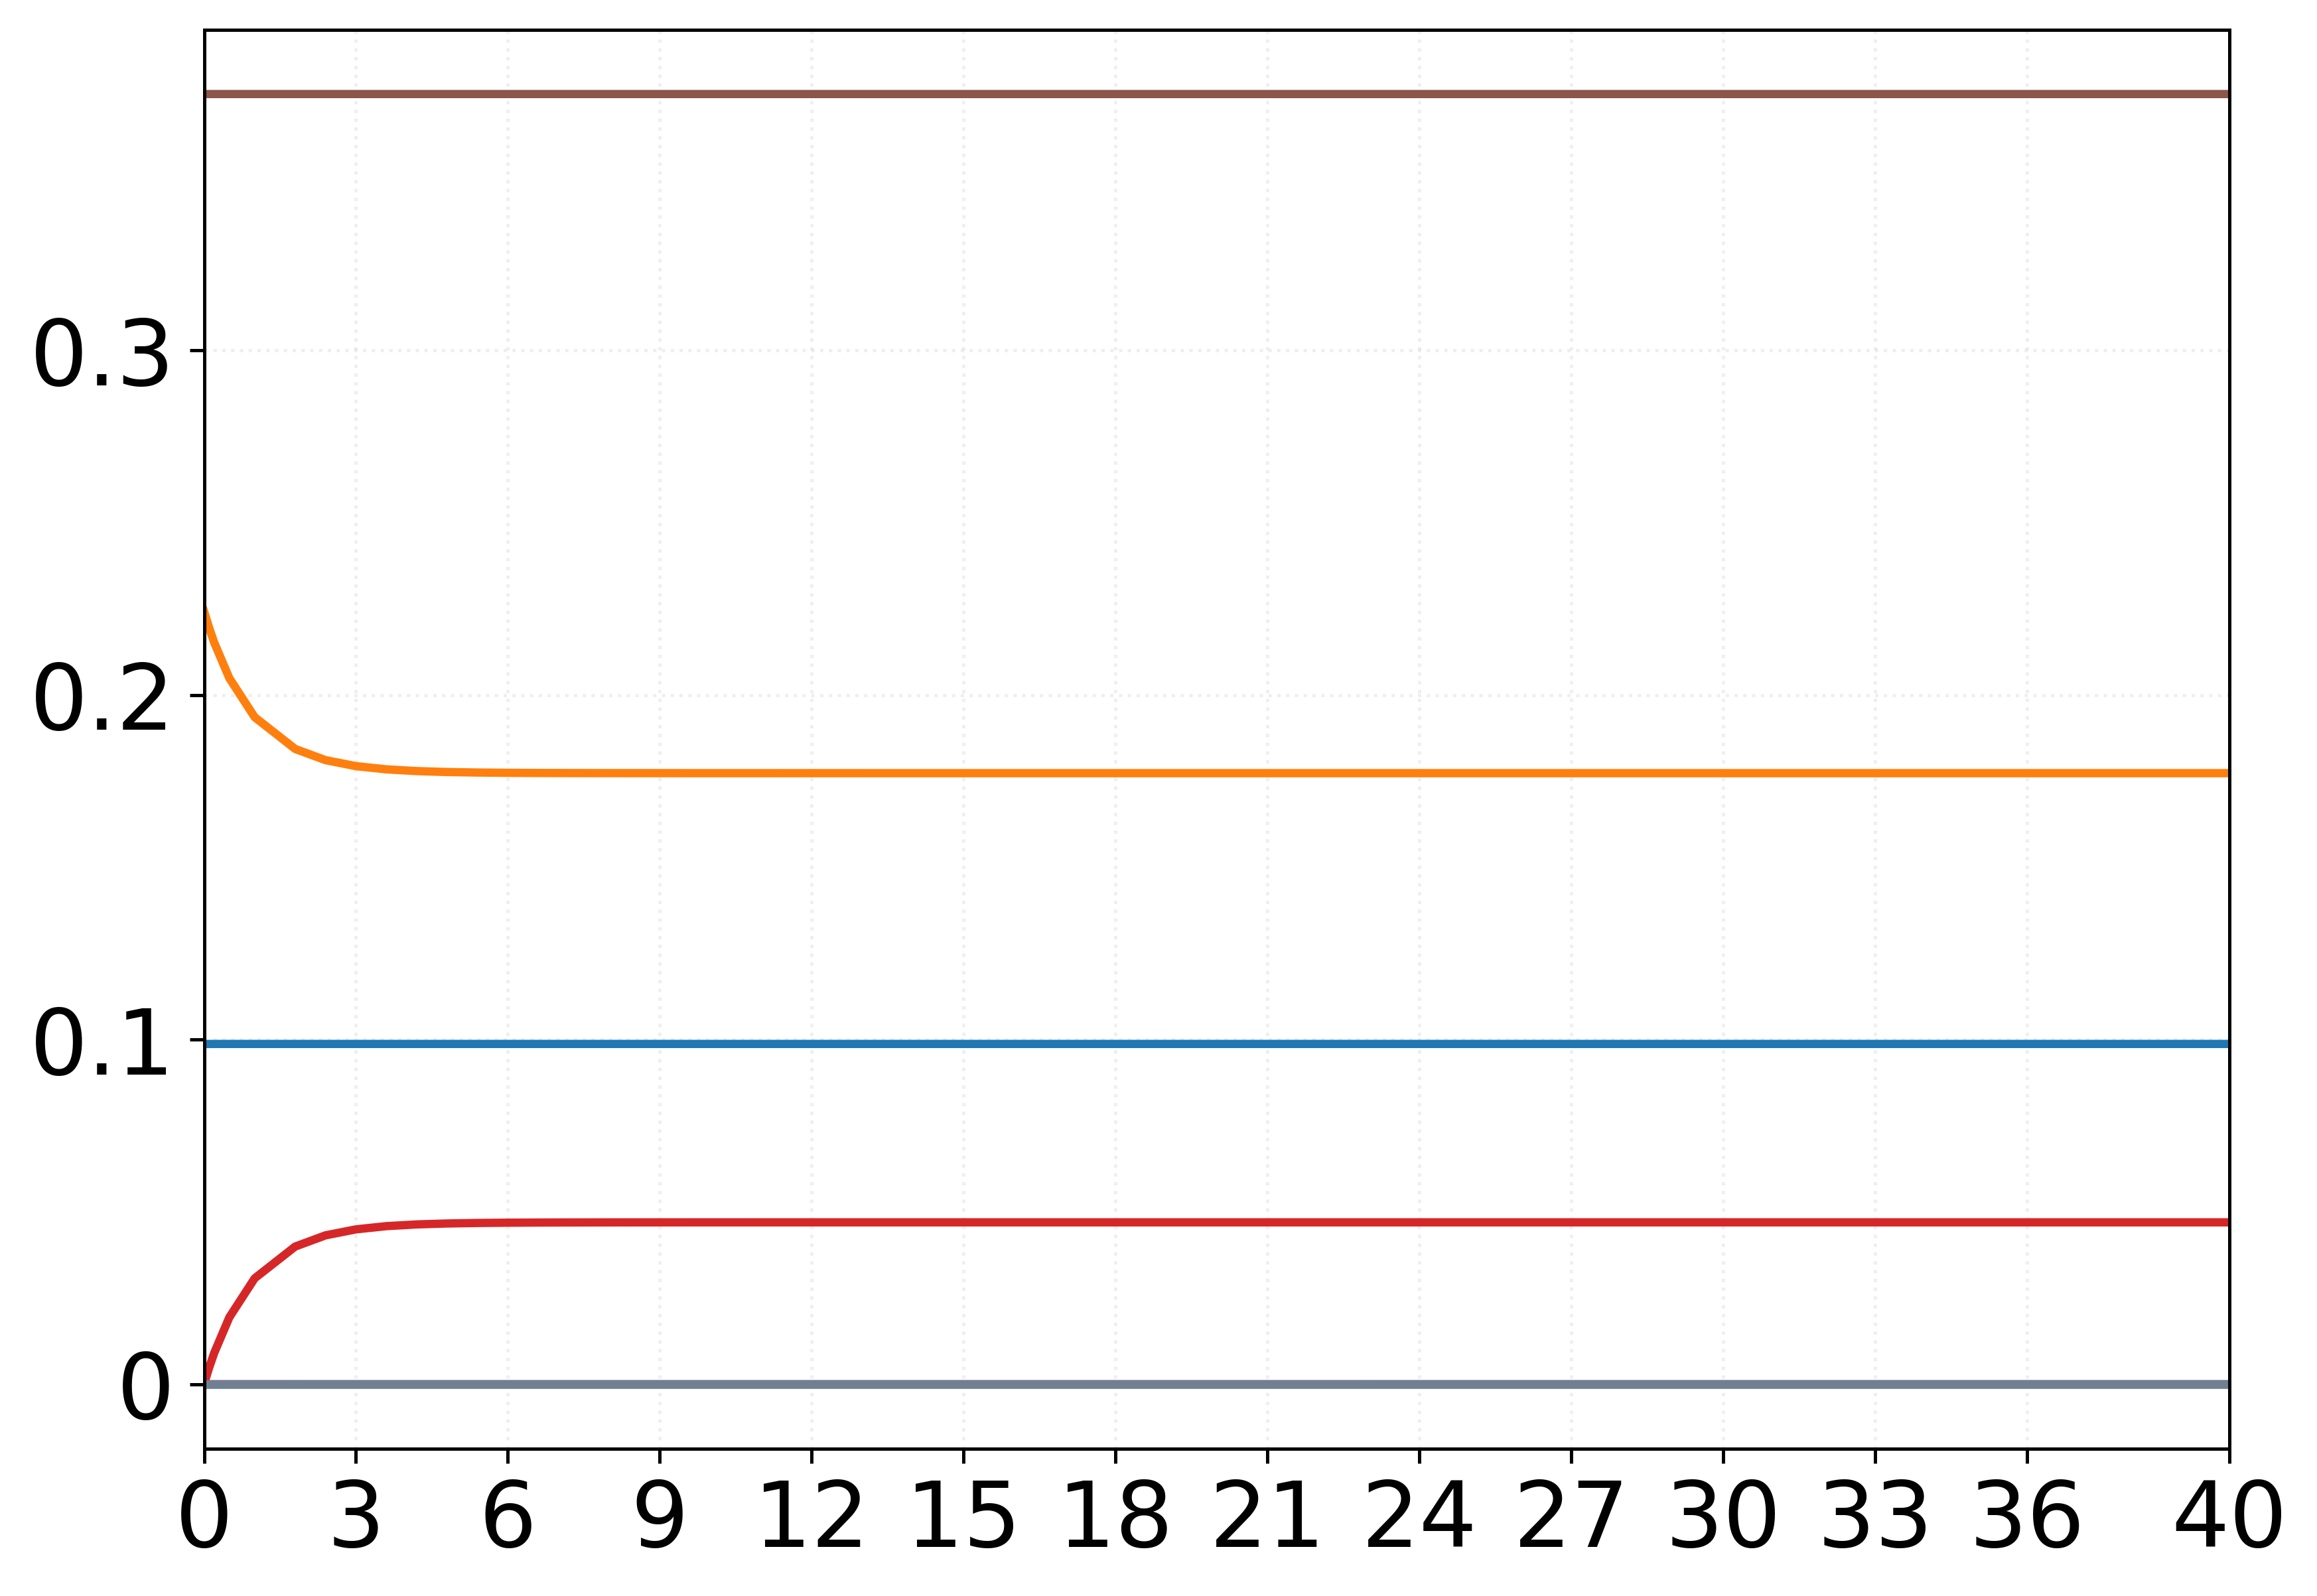

In [68]:
# Same species/time points as the previous cell, but Starve-style formatting
ampk_mtor_ulk_species = ('AMPK', 'ULK', 'AMPKA', 'ULKA', 'MTOR', 'MTORA', 'RKMTORA')
figs_mau = plot_compare_summary_ampk(
    df_dict_a=mechs['rap'].orig_time_sim_df,
    df_dict_b=mechs['no_rap'].orig_time_sim_df,
    label_a='RAP',
    label_b='NO RAP',
    species=ampk_mtor_ulk_species,
    scaling_factor=1e9,
    layout_mode="condition",
    show_iqr=False, show_p80=False,
    show_mean=True, show_median=False,
    sample_trajs=0,
    legend_loc="none",
    separate_conditions=True,
    #curve_labels=True,
    curve_label_xfrac=20,
    curve_label_xpad=1.5,
    curve_label_y_offset_frac=0.02,
    species_colors={'RKMTORA': 'slategray'},
    figsize=(8, 6),
    time_points=t,
    time_units='min',
    x_tick_count=15,
    y_tick_count=5,
    title="",
    font_sizes=font_sizes,
    x_label="",
    y_label="",
    fig_dpi=450,
    user_ylim=(0, 7),
)

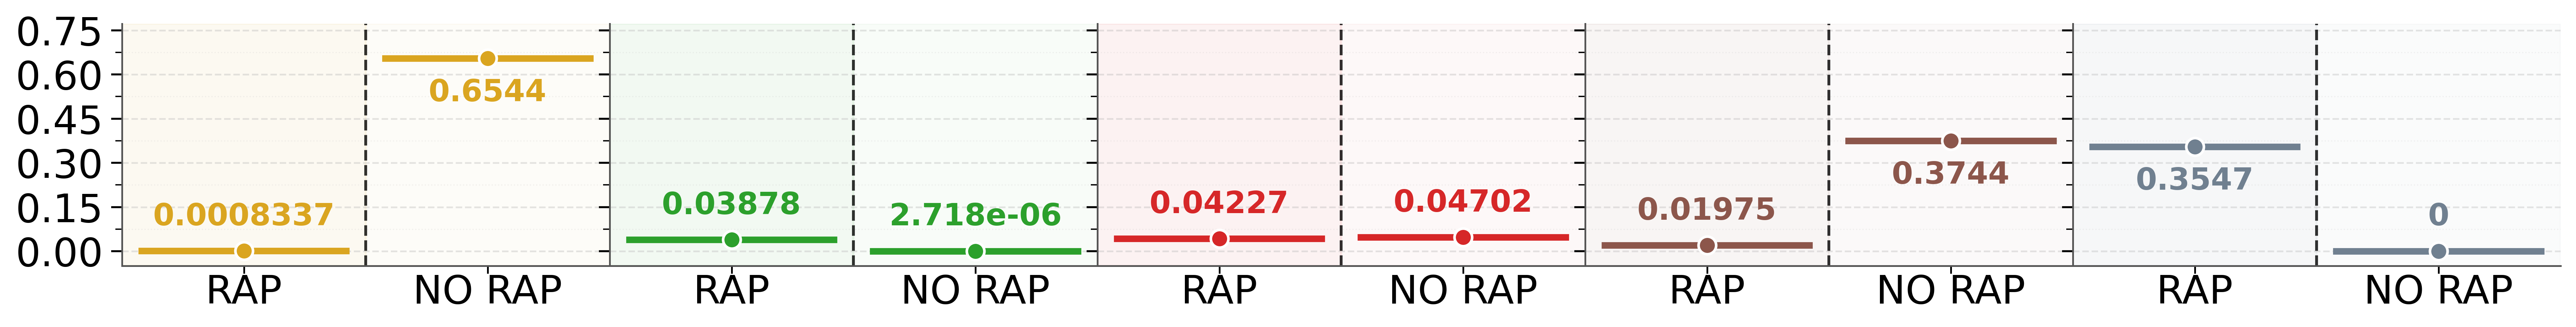

In [69]:
concept_font_sizes["ticks"] = 18

ampk_mtor_ulk_endpoint_fig = plot_endpoint_concept_diagrams(
    df_dict_starvation=mechs['rap'].orig_time_sim_df,
    df_dict_basal=mechs['no_rap'].orig_time_sim_df,
    species=('FKBP12', 'AMPKA', 'ULKA', 'MTORA', 'RKMTORA'),
    scaling_factor=1e9,
    color_species_order=ampk_mtor_ulk_species,
    condition_labels=('RAP', 'NO RAP'),
    endpoint_statistic='mean',
    legend_loc='none',
    font_sizes=concept_font_sizes,
    species_colors={'FKBP12': 'goldenrod', 'RKMTORA': 'slategray'},
    x_label="",
    y_label="",
    title="",
    figsize=(4, 2),
    y_major_ticks=6,
    shared_y_limits=True,
    y_bottom=-0.05,
    transparent_bg=True,
    lower_text_th=0.0,
    upper_text_th=0.3,
    plot_combined=True,
    combined_orientation='horizontal',
    x_pad=0,
    fig_dpi=450,
)